# Лабораторная работа №3. Кластеризация

**Тема:** сегментация заёмщиков по финансовому поведению (Credit Risk Benchmark Dataset)

**Методы:** K-means и иерархическая агломеративная кластеризация (метод Уорда); дополнительно — исследование DBSCAN.

## 1. Введение

**Цель работы:** изучить алгоритмы кластеризации, получить навыки оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**

1. Загрузить датасет, провести дескриптивный анализ: размерность, типы признаков, пропуски, распределения (близость к нормальному), информационная значимость признаков, выбросы; проверить условия применимости кластеризации.
2. Масштабировать признаки и обосновать выбор метода; построить матрицу диаграмм рассеивания и оценить предполагаемую кластерную структуру; аргументировать выбор методов.
3. Выполнить кластеризацию двумя методами — **K-means** и **иерархической кластеризацией (Ward)**; подобрать число кластеров методом локтя, силуэтным анализом и по дендрограмме.
4. Рассчитать внутренние метрики (силуэт, Калинский–Харабаз, Дэвис–Болдин), геометрические характеристики (центры, внутри- и межкластерные расстояния, компактность) и внешние метрики (Rand, ARI, Жаккар и др.) относительно известного класса.
5. Исследовать влияние параметров: k, `init`, `n_init` для K-means; тип связи для иерархической кластеризации; `eps` и `min_samples` для DBSCAN.
6. Визуализировать кластеры (PCA), проанализировать центры, дать содержательную интерпретацию групп и сравнить методы, в том числе по устойчивости.

**Рабочая гипотеза.** Заёмщики делятся на несколько групп по «кредитному поведению»: благополучные клиенты с длинной кредитной историей и низкой загрузкой лимитов, клиенты с ограниченной историей и доходом, а также проблемные заёмщики с просрочками. Если гипотеза верна, кластеры будут заметно различаться по доле просрочек `dlq_2yrs`, хотя сама метка в обучении не участвует.

## 2. Описание датасета и дескриптивный анализ

**Источник:** [Credit Risk Benchmark Dataset](https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset) (Kaggle). Это сбалансированная выборка из известного набора *Give Me Some Credit*: 16 714 заёмщиков, 10 числовых признаков и бинарный класс.

| Признак | Смысл |
|---|---|
| `rev_util` | доля использования возобновляемых кредитных лимитов (кредитные карты) |
| `age` | возраст заёмщика, лет |
| `late_30_59`, `late_60_89`, `late_90` | число просрочек на 30–59, 60–89 и 90+ дней |
| `debt_ratio` | долговая нагрузка: ежемесячные платежи / месячный доход |
| `monthly_inc` | месячный доход |
| `open_credit` | число открытых кредитов и кредитных линий |
| `real_estate` | число ипотечных кредитов и кредитов под залог недвижимости |
| `dependents` | число иждивенцев |
| `dlq_2yrs` | **класс:** была ли серьёзная просрочка (90+ дней) за последние 2 года |

Датасет изначально предназначен для классификации. В задании это допускается («датасет для задачи кластеризации / классификации»). Класс `dlq_2yrs` **исключается из обучения** и используется только для внешней оценки качества кластеров.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import cdist

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score, normalized_mutual_info_score, fowlkes_mallows_score,
    homogeneity_completeness_v_measure,
)
from sklearn.metrics.cluster import pair_confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

FEATURE_RU = {
    "rev_util":    "Использование кредитного лимита",
    "age":         "Возраст",
    "late_30_59":  "Просрочки 30–59 дн.",
    "debt_ratio":  "Долговая нагрузка",
    "monthly_inc": "Месячный доход",
    "open_credit": "Открытые кредиты",
    "late_90":     "Просрочки 90+ дн.",
    "real_estate": "Ипотечные кредиты",
    "late_60_89":  "Просрочки 60–89 дн.",
    "dependents":  "Иждивенцы",
    "dlq_2yrs":    "Просрочка за 2 года (класс)",
}

In [2]:
df_raw = pd.read_csv("data/credit_risk.csv")
TARGET = "dlq_2yrs"
FEATURES = [c for c in df_raw.columns if c != TARGET]

print("Размерность:", df_raw.shape)
print("Пропусков всего:", int(df_raw.isna().sum().sum()))
print("Полных дубликатов:", int(df_raw.duplicated().sum()))
info = pd.DataFrame({
    "описание": [FEATURE_RU[c] for c in df_raw.columns],
    "тип": df_raw.dtypes.astype(str).values,
    "уникальных": df_raw.nunique().values,
    "пропусков": df_raw.isna().sum().values,
    "доля нулей": (df_raw == 0).mean().round(3).values,
}, index=df_raw.columns)
display(info)
display(df_raw.head())

Размерность: (16714, 11)
Пропусков всего: 0
Полных дубликатов: 2


,описание,тип,уникальных,пропусков,доля нулей
rev_util,Использование кредитного лимита,float64,13887,0,0.053
age,Возраст,float64,78,0,0.000
late_30_59,Просрочки 30–59 дн.,float64,16,0,0.679
debt_ratio,Долговая нагрузка,float64,16128,0,0.024
monthly_inc,Месячный доход,float64,5150,0,0.011
open_credit,Открытые кредиты,float64,48,0,0.022
late_90,Просрочки 90+ дн.,float64,18,0,0.815
real_estate,Ипотечные кредиты,float64,20,0,0.396
late_60_89,Просрочки 60–89 дн.,float64,12,0,0.850
dependents,Иждивенцы,float64,9,0,0.507


,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
0,0.007,38.0,0.0,0.302,5440.0,4.0,0.0,1.0,0.0,3.0,0
1,0.705,63.0,0.0,0.471,8000.0,9.0,0.0,1.0,0.0,0.0,0
2,0.063,57.0,0.0,0.069,5000.0,17.0,0.0,0.0,0.0,0.0,0
3,0.368,68.0,0.0,0.296,6250.0,16.0,0.0,2.0,0.0,0.0,0
4,1.000,34.0,1.0,0.000,3500.0,0.0,0.0,0.0,0.0,1.0,0


In [3]:
desc = df_raw[FEATURES].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["асимметрия"] = df_raw[FEATURES].skew()
desc["эксцесс"] = df_raw[FEATURES].kurt()
display(desc)
print("Баланс классов:")
display(df_raw[TARGET].value_counts().rename("кол-во").to_frame().assign(доля=lambda t: t["кол-во"] / len(df_raw)))

,count,mean,std,min,1%,25%,50%,75%,99%,max,асимметрия,эксцесс
rev_util,16714.0,4.800,204.062,0.0,0.0,0.082,0.443,0.927,1.448,22000.0,82.391,8275.510
age,16714.0,48.799,13.906,21.0,24.0,38.000,48.000,58.000,84.000,101.0,0.361,-0.292
late_30_59,16714.0,1.110,7.173,0.0,0.0,0.000,0.000,1.000,6.000,98.0,13.104,173.874
debt_ratio,16714.0,30.980,719.695,0.0,0.0,0.156,0.322,0.533,367.620,61106.5,61.240,4549.802
monthly_inc,16714.0,6118.120,5931.842,0.0,0.0,3128.500,5000.000,7573.000,24166.000,250000.0,11.951,352.594
open_credit,16714.0,8.504,5.371,0.0,0.0,5.000,8.000,11.000,25.000,57.0,1.168,3.002
late_90,16714.0,0.864,7.168,0.0,0.0,0.000,0.000,0.000,6.000,98.0,13.236,176.216
real_estate,16714.0,1.047,1.273,0.0,0.0,0.000,1.000,2.000,5.000,29.0,3.573,37.323
late_60_89,16714.0,0.734,7.139,0.0,0.0,0.000,0.000,0.000,4.000,98.0,13.444,180.095
dependents,16714.0,0.944,1.199,0.0,0.0,0.000,0.000,2.000,4.000,8.0,1.280,1.392


Баланс классов:


,кол-во,доля
dlq_2yrs,,
0,8357,0.5
1,8357,0.5


**Пояснение к датасету.**

* Размерность — **16 714 × 11**: 10 признаков-предикторов и класс. Все признаки числовые (`float64`), класс — `int64`. **Пропусков нет**, полных дубликатов всего 2, они не влияют на результат.
* По смыслу признаки делятся на непрерывные (`rev_util`, `debt_ratio`, `monthly_inc`, `age`) и дискретные счётчики (просрочки, кредиты, иждивенцы). У счётчиков просрочек от 68% до 85% нулей.
* Классы сбалансированы ровно 50/50 (по 8 357 объектов). Поэтому внешние метрики не искажаются дисбалансом.
* Описательная статистика сразу показывает аномалии. Максимум `rev_util` равен 22 000 при медиане 0.44: доля использования лимита не может быть такой. Максимум `debt_ratio` равен 61 106 при медиане 0.32. В счётчиках просрочек встречается значение 98 при 99-м перцентиле 6. Медиана и среднее у этих признаков различаются на порядки.

### 2.1. Распределения признаков и проверка нормальности

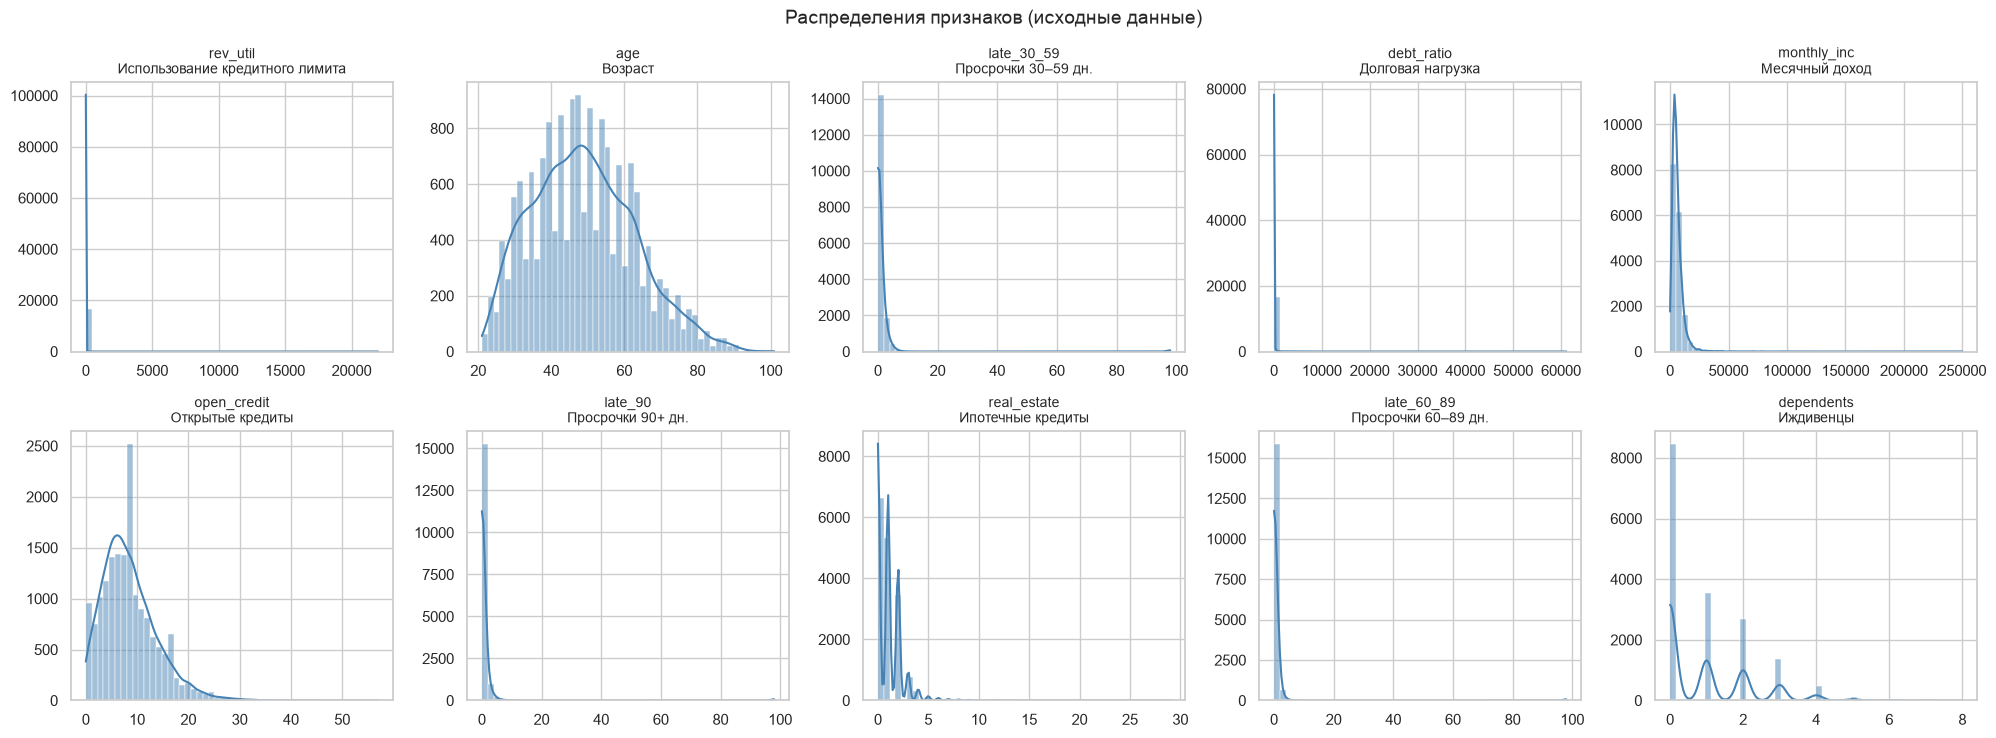

,асимметрия,эксцесс,p (Д'Агостино),"W (Шапиро, n=500)","p (Шапиро, n=500)",нормальное?
rev_util,82.391,8275.510,0.000e+00,0.029,2.571e-44,нет
age,0.361,-0.292,7.507e-93,0.983,1.848e-05,нет
late_30_59,13.104,173.874,0.000e+00,0.112,4.972e-43,нет
debt_ratio,61.240,4549.802,0.000e+00,0.038,3.525e-44,нет
monthly_inc,11.951,352.594,0.000e+00,0.888,1.475e-18,нет
open_credit,1.168,3.002,0.000e+00,0.931,1.914e-14,нет
late_90,13.236,176.216,0.000e+00,0.098,2.991e-43,нет
real_estate,3.573,37.323,0.000e+00,0.725,6.729e-28,нет
late_60_89,13.444,180.095,0.000e+00,0.081,1.637e-43,нет
dependents,1.280,1.392,0.000e+00,0.779,2.030e-25,нет


In [4]:
def plot_hists(data, title, bins=50):
    fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
    for ax, col in zip(axes.ravel(), FEATURES):
        sns.histplot(data[col], bins=bins, kde=True, ax=ax, color="steelblue")
        ax.set_title(f"{col}\n{FEATURE_RU[col]}", fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_hists(df_raw, "Распределения признаков (исходные данные)")

# Проверка нормальности: тест Д'Агостино–Пирсона (n велико) и Шапиро–Уилка на подвыборке 500
rng = np.random.default_rng(SEED)
sub = df_raw[FEATURES].sample(500, random_state=SEED)
norm_tab = pd.DataFrame({
    "асимметрия": df_raw[FEATURES].skew(),
    "эксцесс": df_raw[FEATURES].kurt(),
    "p (Д'Агостино)": [stats.normaltest(df_raw[c]).pvalue for c in FEATURES],
    "W (Шапиро, n=500)": [stats.shapiro(sub[c]).statistic for c in FEATURES],
    "p (Шапиро, n=500)": [stats.shapiro(sub[c]).pvalue for c in FEATURES],
})
norm_tab["нормальное?"] = np.where(norm_tab["p (Шапиро, n=500)"] > 0.05, "да", "нет")
display(norm_tab)

**Пояснение к распределениям.**

* **Ни один признак не распределён нормально.** Тест Д'Агостино–Пирсона на всей выборке и тест Шапиро–Уилка на подвыборке из 500 объектов отвергают нормальность для всех 10 признаков (p < 10⁻⁴).
* Ближе всего к нормальному `age`: асимметрия 0.36, эксцесс −0.29, W = 0.98. Распределение одновершинное, слегка скошено вправо.
* У `rev_util`, `debt_ratio`, `monthly_inc` и трёх счётчиков просрочек экстремальная правая асимметрия (от 12 до 82) и огромный эксцесс. Гистограммы фактически вырождаются в один столбик у нуля и редкие далёкие значения. Это следствие выбросов и аномальных кодов.
* `open_credit`, `real_estate` и `dependents` — счётчики с умеренной правой асимметрией (от 1.2 до 3.6), их форма близка к пуассоновской.

**Вывод:** перед кластеризацией нужно убрать аномалии и уменьшить асимметрию. K-means и метод Уорда минимизируют сумму квадратов расстояний, поэтому длинные хвосты и экстремальные значения сильно смещают центры.

### 2.2. Анализ выбросов

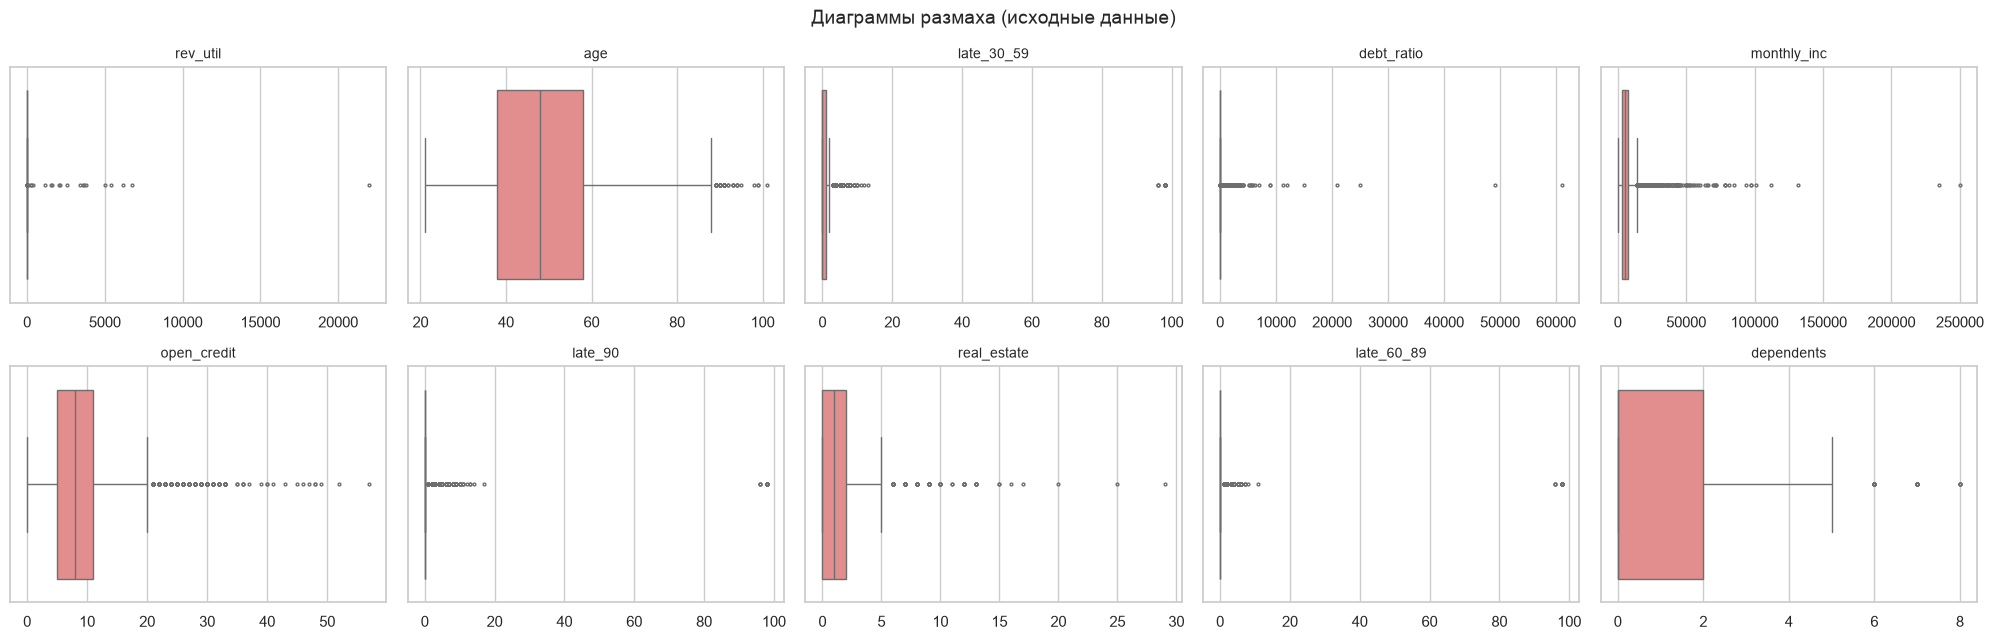

,выбросов IQR (1.5),выбросов |z|>3,максимум,99-й перцентиль,"доля IQR, %"
rev_util,50,15,22000.0,1.448,0.30
age,56,26,101.0,84.000,0.34
late_30_59,1242,89,98.0,6.000,7.43
debt_ratio,1031,56,61106.5,367.620,6.17
monthly_inc,779,175,250000.0,24166.000,4.66
open_credit,485,175,57.0,25.000,2.90
late_90,3088,89,98.0,6.000,18.48
real_estate,162,273,29.0,5.000,0.97
late_60_89,2514,89,98.0,4.000,15.04
dependents,48,163,8.0,4.000,0.29


,строк
служебные коды 96/98 в просрочках,89
доход < 100 (0 или 1),254
rev_util > 2,61
любая аномалия,401


Медиана debt_ratio при доходе < 100: 879.0 | при доходе >= 100: 0.318


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 6.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=df_raw[col], ax=ax, color="lightcoral", fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Диаграммы размаха (исходные данные)", fontsize=14)
plt.tight_layout()
plt.show()

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr))

out_tab = pd.DataFrame({
    "выбросов IQR (1.5)": [int(iqr_outliers(df_raw[c]).sum()) for c in FEATURES],
    "выбросов |z|>3": [int((np.abs(stats.zscore(df_raw[c])) > 3).sum()) for c in FEATURES],
    "максимум": df_raw[FEATURES].max().values,
    "99-й перцентиль": df_raw[FEATURES].quantile(.99).values,
}, index=FEATURES)
out_tab["доля IQR, %"] = (out_tab["выбросов IQR (1.5)"] / len(df_raw) * 100).round(2)
display(out_tab)

late_cols = ["late_30_59", "late_60_89", "late_90"]
anom = pd.DataFrame({
    "служебные коды 96/98 в просрочках": (df_raw[late_cols] >= 96).any(axis=1),
    "доход < 100 (0 или 1)": df_raw["monthly_inc"] < 100,
    "rev_util > 2": df_raw["rev_util"] > 2,
})
anom["любая аномалия"] = anom.any(axis=1)
display(anom.sum().rename("строк").to_frame())
print("Медиана debt_ratio при доходе < 100:", df_raw.loc[anom["доход < 100 (0 или 1)"], "debt_ratio"].median(),
      "| при доходе >= 100:", round(df_raw.loc[~anom["доход < 100 (0 или 1)"], "debt_ratio"].median(), 3))

**Пояснение к выбросам.** Есть два разных вида «выбросов», и обрабатывать их нужно по-разному.

1. **Ошибки и служебные коды. Их удаляем: 401 строка, 2.4%.**
   * Значения **96/98 в счётчиках просрочек** (89 строк). В исходном наборе *Give Me Some Credit* это известные служебные коды, а не реальное число просрочек: 98 просрочек за 2 года физически невозможны.
   * **Доход 0 или 1** (254 строки). В этих строках `debt_ratio` теряет смысл: медиана равна 879 против 0.32 у остальных, то есть в поле записана сумма долга, а не отношение. Предварительный эксперимент показал, что без удаления эти 250 объектов образуют отдельный «кластер ошибок данных».
   * **`rev_util > 2`** (61 строка): использование лимита больше 200% нереалистично. Значения в тысячи — ошибки ввода.
2. **Статистические выбросы по IQR. Их сохраняем и смягчаем.** По правилу 1.5·IQR за усы выходит до 18% наблюдений у `late_90` и 15% у `late_60_89`. Но это не ошибки: при медиане 0 любой заёмщик хотя бы с одной просрочкой формально становится «выбросом». Удалять их нельзя, иначе пропадёт именно та группа рискованных клиентов, которую мы хотим найти. Поэтому применяем винзоризацию по 1-му и 99-му перцентилям и логарифмирование (раздел 3).

### 2.3. Информационная значимость признаков

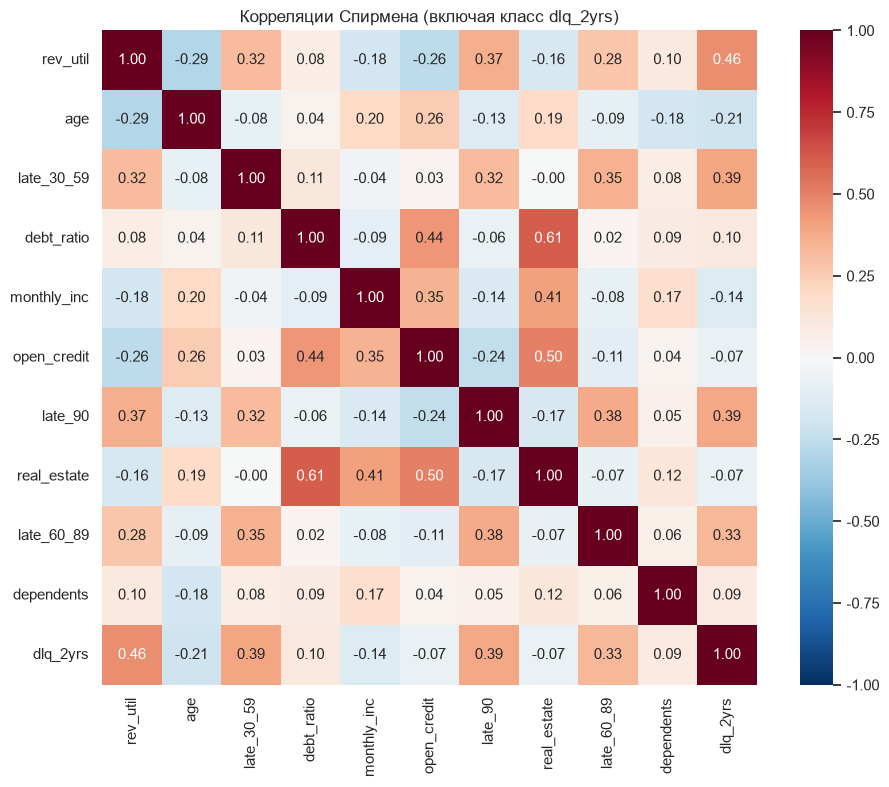

,коэф. вариации,уникальных,|ρ| с классом,взаимная информация с классом,макс. |ρ| с другим признаком
rev_util,42.514,13887,0.463,0.121,0.367
late_90,8.297,18,0.386,0.089,0.378
late_30_59,6.461,16,0.393,0.081,0.354
late_60_89,9.721,12,0.331,0.066,0.378
age,0.285,78,0.206,0.024,0.290
debt_ratio,23.231,16128,0.103,0.017,0.605
monthly_inc,0.970,5150,0.136,0.013,0.410
real_estate,1.215,20,0.066,0.012,0.605
open_credit,0.632,48,0.068,0.009,0.504
dependents,1.269,9,0.090,0.003,0.180


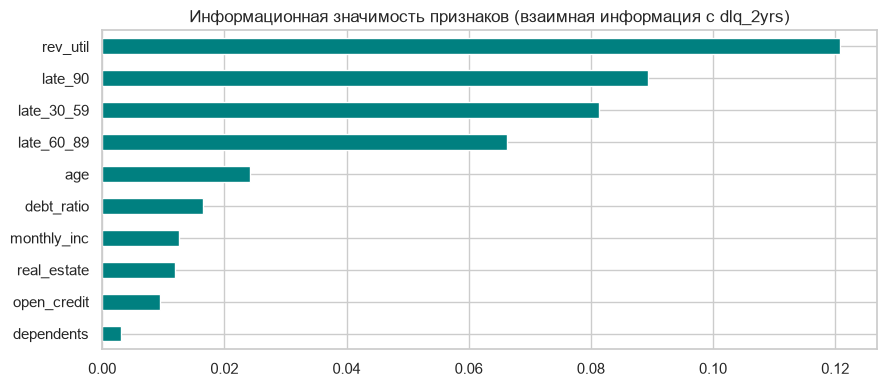

In [6]:
corr = df_raw.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Корреляции Спирмена (включая класс dlq_2yrs)")
plt.tight_layout()
plt.show()

mi = mutual_info_classif(df_raw[FEATURES], df_raw[TARGET], random_state=SEED)
inf_tab = pd.DataFrame({
    "коэф. вариации": (df_raw[FEATURES].std() / df_raw[FEATURES].mean()).values,
    "уникальных": df_raw[FEATURES].nunique().values,
    "|ρ| с классом": corr.loc[FEATURES, TARGET].abs().values,
    "взаимная информация с классом": mi,
    "макс. |ρ| с другим признаком": [corr.loc[c, [f for f in FEATURES if f != c]].abs().max() for c in FEATURES],
}, index=FEATURES).sort_values("взаимная информация с классом", ascending=False)
display(inf_tab)

fig, ax = plt.subplots(figsize=(9, 4))
inf_tab["взаимная информация с классом"].plot.barh(ax=ax, color="teal")
ax.invert_yaxis()
ax.set_title("Информационная значимость признаков (взаимная информация с dlq_2yrs)")
plt.tight_layout()
plt.show()

**Пояснение к информативности.**

* **Изменчивость.** У всех признаков ненулевая дисперсия и достаточно уникальных значений, константных и квазиконстантных признаков нет. Минимальный коэффициент вариации у `age` (0.29), но для возраста это нормальная изменчивость.
* **Связь с классом** (взаимная информация и корреляция Спирмена). Сильнее всего с просрочкой связаны `rev_util` (MI = 0.121, |ρ| = 0.46) и три счётчика просрочек (MI от 0.07 до 0.09, |ρ| от 0.33 до 0.39). Затем идут `age` (чем старше, тем ниже риск) и `monthly_inc`. Слабее всего связаны `dependents`, `open_credit` и `real_estate`.
* **Мультиколлинеарность умеренная:** максимальная |ρ| = 0.61 (между `debt_ratio` и `real_estate`, так как ипотека увеличивает платежи). Счётчики просрочек коррелируют между собой примерно на 0.35–0.38. Явно дублирующих признаков (|ρ| > 0.8) нет, поэтому для кластеризации оставлены **все 10 признаков**.
* Признаки, слабо связанные с классом, всё равно полезны для кластеризации. Они описывают «жизненный этап» клиента (ипотека, число кредитов, иждивенцы) и могут разделять группы, которые не совпадают с делением «просрочка / нет просрочки».

### 2.4. Проверка условий применимости кластеризации

| Условие | Выполнение |
|---|---|
| **Отсутствие классов** | В данных есть метка `dlq_2yrs`, но она **исключена из матрицы признаков**. Алгоритмы её не видят, она нужна только для внешней проверки (п. 4.3). |
| **Осмысленность кластеризации** | Сегментация заёмщиков — стандартная банковская задача: дифференцированные лимиты, ставки и коммуникация. Ожидаемые сегменты (благополучные / ограниченная история / проблемные) легко интерпретировать. Кластерную тенденцию дополнительно проверяем статистикой Хопкинса (п. 3.2). |
| **Отсутствие выбросов** | Аномальные записи (коды 96/98, нулевой доход, `rev_util` > 2) удаляются. Длинные хвосты обрезаются по 1/99-му перцентилям и сжимаются логарифмом (раздел 3). |
| **Числовые признаки, сопоставимый масштаб** | Все признаки числовые. Масштабы отличаются на 4 порядка (доход ~10³–10⁴, доли ~10⁻¹), поэтому нужна стандартизация. |

## 3. Предобработка данных

Конвейер предобработки:

1. **Удаление аномалий** (п. 2.2) — 401 строка.
2. **Винзоризация** каждого признака по 1-му и 99-му перцентилям. Экстремальные значения не удаляются, а заменяются граничными.
3. **Логарифмирование `log1p`** признаков с правосторонней асимметрией: `rev_util`, `debt_ratio`, `monthly_inc`, счётчики. `log1p(x) = ln(1+x)` корректно обрабатывает нули. `age` распределён почти симметрично, его не логарифмируем.
4. **Стандартизация `StandardScaler`**: z = (x − μ)/σ.

Класс `y = dlq_2yrs` отделяется до обучения.

In [7]:
# 1) удаление аномальных записей (ошибки данных, а не «редкие клиенты»)
df = df_raw.loc[~anom["любая аномалия"]].reset_index(drop=True)
y = df[TARGET].values                       # класс: НЕ используется при обучении
X_raw = df[FEATURES].copy()
print(f"Удалено аномальных строк: {len(df_raw) - len(df)} ({(len(df_raw) - len(df)) / len(df_raw):.2%}); осталось {len(df)}")

# 2) винзоризация хвостов по 1-му и 99-му перцентилям
lo, hi = X_raw.quantile(.01), X_raw.quantile(.99)
X_w = X_raw.clip(lower=lo, upper=hi, axis=1)

# 3) логарифмирование признаков с правосторонней асимметрией
LOG_COLS = ["rev_util", "debt_ratio", "monthly_inc", "open_credit", "real_estate",
            "dependents", "late_30_59", "late_60_89", "late_90"]
X_t = X_w.copy()
X_t[LOG_COLS] = np.log1p(X_t[LOG_COLS])

# 4) стандартизация
scaler = StandardScaler()
Z = scaler.fit_transform(X_t)
Zdf = pd.DataFrame(Z, columns=FEATURES)

skew_cmp = pd.DataFrame({
    "асимметрия исходн.": X_raw.skew(),
    "после винзоризации": X_w.skew(),
    "после log1p": X_t.skew(),
    "среднее после Z": Zdf.mean().round(6).values,
    "СКО после Z": Zdf.std(ddof=0).round(6).values,
    "|z|>3 после обработки": (np.abs(Zdf) > 3).sum().values,
})
display(skew_cmp)

Удалено аномальных строк: 401 (2.40%); осталось 16313


,асимметрия исходн.,после винзоризации,после log1p,среднее после Z,СКО после Z,|z|>3 после обработки
rev_util,0.286,0.195,0.011,-0.0,1.0,0
age,0.364,0.325,0.325,0.0,1.0,0
late_30_59,2.686,2.188,1.337,0.0,1.0,0
debt_ratio,70.209,2.251,1.185,0.0,1.0,293
monthly_inc,12.135,1.816,-0.227,-0.0,1.0,0
open_credit,1.187,0.825,-0.827,0.0,1.0,272
late_90,4.658,2.955,2.197,-0.0,1.0,641
real_estate,3.584,1.223,0.234,-0.0,1.0,0
late_60_89,4.205,3.102,2.435,-0.0,1.0,721
dependents,1.284,1.044,0.492,0.0,1.0,0


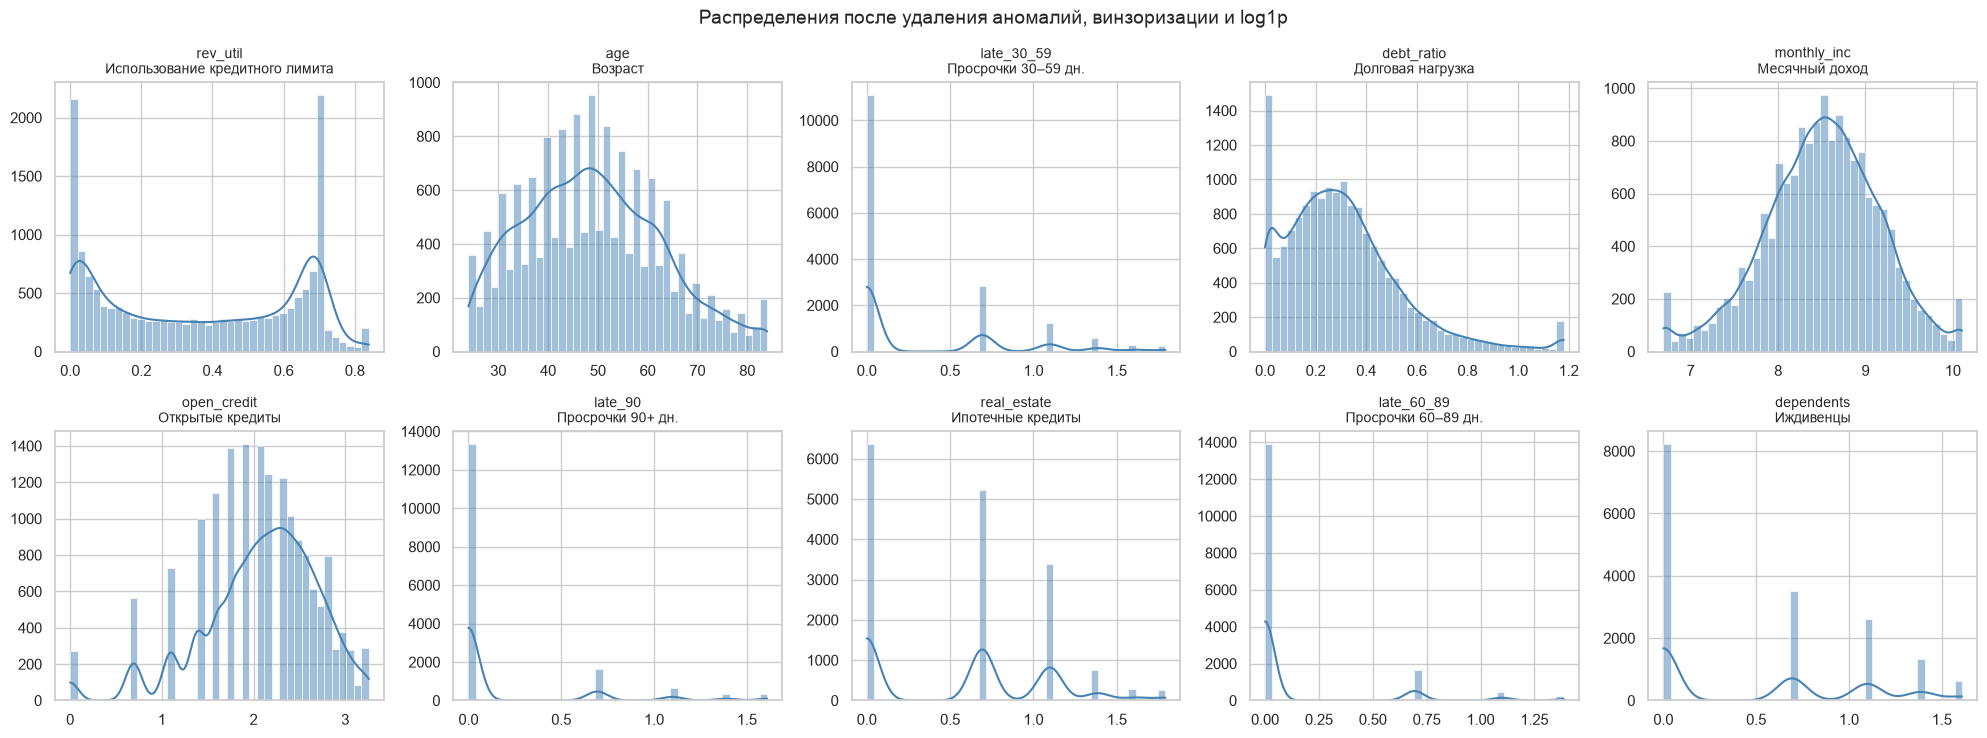

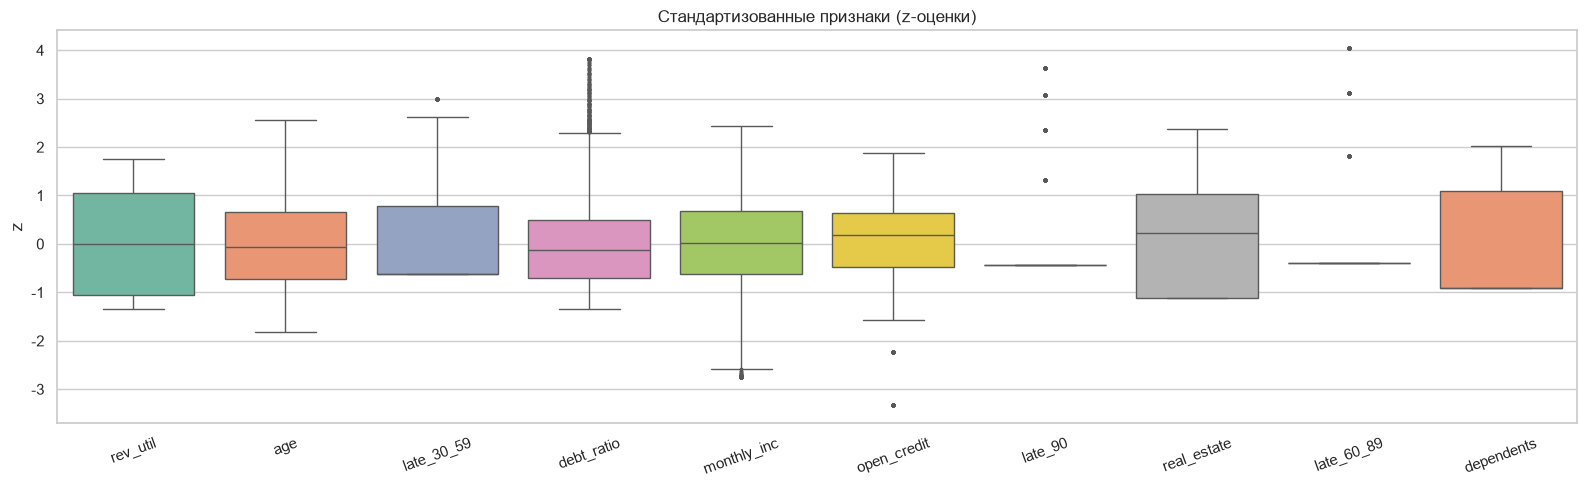

In [8]:
plot_hists(X_t, "Распределения после удаления аномалий, винзоризации и log1p", bins=40)

fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=Zdf, ax=ax, palette="Set2", fliersize=1.5)
ax.set_title("Стандартизованные признаки (z-оценки)")
ax.set_ylabel("z")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Пояснение к предобработке.**

* После удаления аномалий осталось **16 313 объектов**.
* Асимметрия резко снизилась: у `debt_ratio` с 70 до 1.2, у `monthly_inc` с 12.1 до −0.2, у `rev_util` с 0.29 до 0.01. Распределения непрерывных признаков стали близки к симметричным, что видно на гистограммах.
* У счётчиков просрочек асимметрия остаётся (от 1.3 до 2.4). Это свойство данных, а не дефект: у большинства заёмщиков просрочек нет. После стандартизации у них остаются значения |z| > 3 (около 4% объектов по `late_60_89`), и это **содержательная информация** о рискованных клиентах.
* После `StandardScaler` у всех признаков среднее 0 и СКО 1. Диаграммы размаха теперь сравнимы, и ни один признак не доминирует в евклидовом расстоянии из-за единиц измерения.

### 3.1. Выбор метода масштабирования

In [9]:
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
rows = []
for name, sc in scalers.items():
    A = sc.fit_transform(X_t)
    km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(A)
    spread = A.std(axis=0)
    rows.append({
        "масштабирование": name,
        "СКО признаков: мин": spread.min(), "СКО признаков: макс": spread.max(),
        "silhouette (k=3)": silhouette_score(A, km.labels_, sample_size=6000, random_state=SEED),
        "Calinski–Harabasz": calinski_harabasz_score(A, km.labels_),
        "Davies–Bouldin": davies_bouldin_score(A, km.labels_),
        "размеры кластеров": np.bincount(km.labels_).tolist(),
    })
display(pd.DataFrame(rows).set_index("масштабирование"))

,СКО признаков: мин,СКО признаков: макс,silhouette (k=3),Calinski–Harabasz,Davies–Bouldin,размеры кластеров
масштабирование,,,,,,
StandardScaler,1.000,1.000,0.177,3106.501,1.847,"[8293, 5395, 2625]"
MinMaxScaler,0.192,0.342,0.171,3407.927,1.714,"[6282, 5098, 4933]"
RobustScaler,0.313,0.902,0.175,3614.415,1.816,"[4740, 4229, 7344]"


**Обоснование выбора StandardScaler.**

* K-means и метод Уорда используют евклидово расстояние, поэтому вклад признака в расстояние пропорционален его дисперсии. **Только StandardScaler даёт всем признакам одинаковую дисперсию (СКО = 1).** У MinMaxScaler СКО признаков от 0.19 до 0.34, у RobustScaler — от 0.31 до 0.90. При этих методах признаки неявно получают разные веса: например, после MinMax счётчики просрочек с длинным хвостом сжимаются сильнее, чем возраст.
* MinMaxScaler чувствителен к выбросам: одно экстремальное значение задаёт весь диапазон. Выбросы мы уже смягчили, но остаточные хвосты счётчиков всё равно сжимают основную массу данных.
* RobustScaler (медиана и IQR) полезен при выбросах. Но у счётчиков с медианой 0 и IQR, близким к 0, он даёт нестабильный масштаб.
* По внутренним метрикам при k = 3 разница невелика: силуэт 0.177 (Standard), 0.171 (MinMax), 0.175 (Robust). CH и DB у MinMax и Robust немного лучше, но лишь потому, что они «прячут» часть признаков. Значит, решающим аргументом служит равный вклад признаков, а не прирост метрик. Это также соответствует методическим рекомендациям к работе.

### 3.2. Кластерная тенденция (статистика Хопкинса) и PCA

Статистика Хопкинса (10 запусков): 0.770 ± 0.005


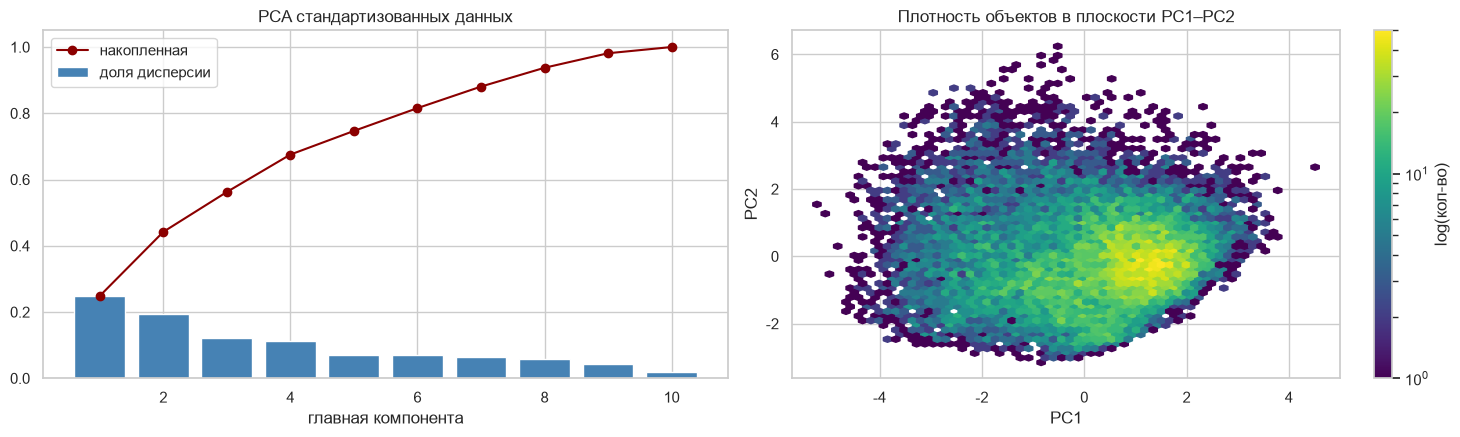

Доля дисперсии PC1+PC2: 0.442 | PC1..PC4: 0.675


,PC1,PC2,PC3
rev_util,-0.383,0.299,-0.025
age,0.293,-0.087,-0.118
late_30_59,-0.179,0.451,0.023
debt_ratio,0.212,0.462,-0.488
monthly_inc,0.321,0.083,0.645
open_credit,0.455,0.279,-0.042
late_90,-0.356,0.271,0.081
real_estate,0.436,0.371,-0.010
late_60_89,-0.252,0.370,0.060
dependents,-0.012,0.230,0.564


In [10]:
def hopkins(A, m=None, seed=SEED):
    """Статистика Хопкинса: ~0.5 — равномерные данные, -> 1 — выраженная кластерная структура."""
    rng = np.random.default_rng(seed)
    n, d = A.shape
    m = m or int(0.05 * n)
    nn = NearestNeighbors(n_neighbors=2).fit(A)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(A[idx], n_neighbors=2)[0][:, 1]                   # расстояние до ближайшего реального соседа
    U = rng.uniform(A.min(axis=0), A.max(axis=0), size=(m, d))
    u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]                         # от случайной точки до данных
    return u.sum() / (u.sum() + w.sum())

H = [hopkins(Z, seed=s) for s in range(10)]
print(f"Статистика Хопкинса (10 запусков): {np.mean(H):.3f} ± {np.std(H):.3f}")

pca_full = PCA().fit(Z)
evr = pca_full.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(range(1, 11), evr, color="steelblue", label="доля дисперсии")
axes[0].plot(range(1, 11), np.cumsum(evr), "o-", color="darkred", label="накопленная")
axes[0].set_xlabel("главная компонента"); axes[0].set_title("PCA стандартизованных данных"); axes[0].legend()
P2 = pca_full.transform(Z)[:, :2]
hb = axes[1].hexbin(P2[:, 0], P2[:, 1], gridsize=60, bins="log", cmap="viridis")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Плотность объектов в плоскости PC1–PC2")
plt.colorbar(hb, ax=axes[1], label="log(кол-во)")
plt.tight_layout()
plt.show()
print("Доля дисперсии PC1+PC2:", round(evr[:2].sum(), 3), "| PC1..PC4:", round(evr[:4].sum(), 3))
loadings = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
display(loadings.round(3))

**Пояснение.**

* **Статистика Хопкинса H = 0.77 ± 0.005** (10 запусков, по 5% объектов). Для равномерно распределённых данных H ≈ 0.5, для выраженной кластерной структуры H → 1. Значение 0.77 означает, что **данные значимо неоднородны и кластеризация осмысленна**. Хорошо разделённых «облаков» при таком значении ждать не стоит: скорее это области повышенной плотности.
* **PCA.** Первые две компоненты объясняют 44% дисперсии, первые четыре — 68%. Поэтому двумерная визуализация лишь приблизительна, и кластеры в ней будут частично перекрываться.
  * **PC1** (25%) — ось «кредитной зрелости»: положительные нагрузки у `open_credit` (+0.46), `real_estate` (+0.44), `monthly_inc` (+0.32) и `age` (+0.29), отрицательные — у `rev_util` (−0.38) и просрочек.
  * **PC2** (19%) — ось «проблемности»: `late_30_59` (+0.45), `late_60_89` (+0.37), `late_90` (+0.27) и `debt_ratio` (+0.46).
* На карте плотности PC1–PC2 видна одна плотная область (благополучные клиенты справа внизу) и «шлейф» в сторону высоких PC2 (заёмщики с просрочками). Резких разрывов между группами нет.

### 3.3. Матрица диаграмм рассеивания

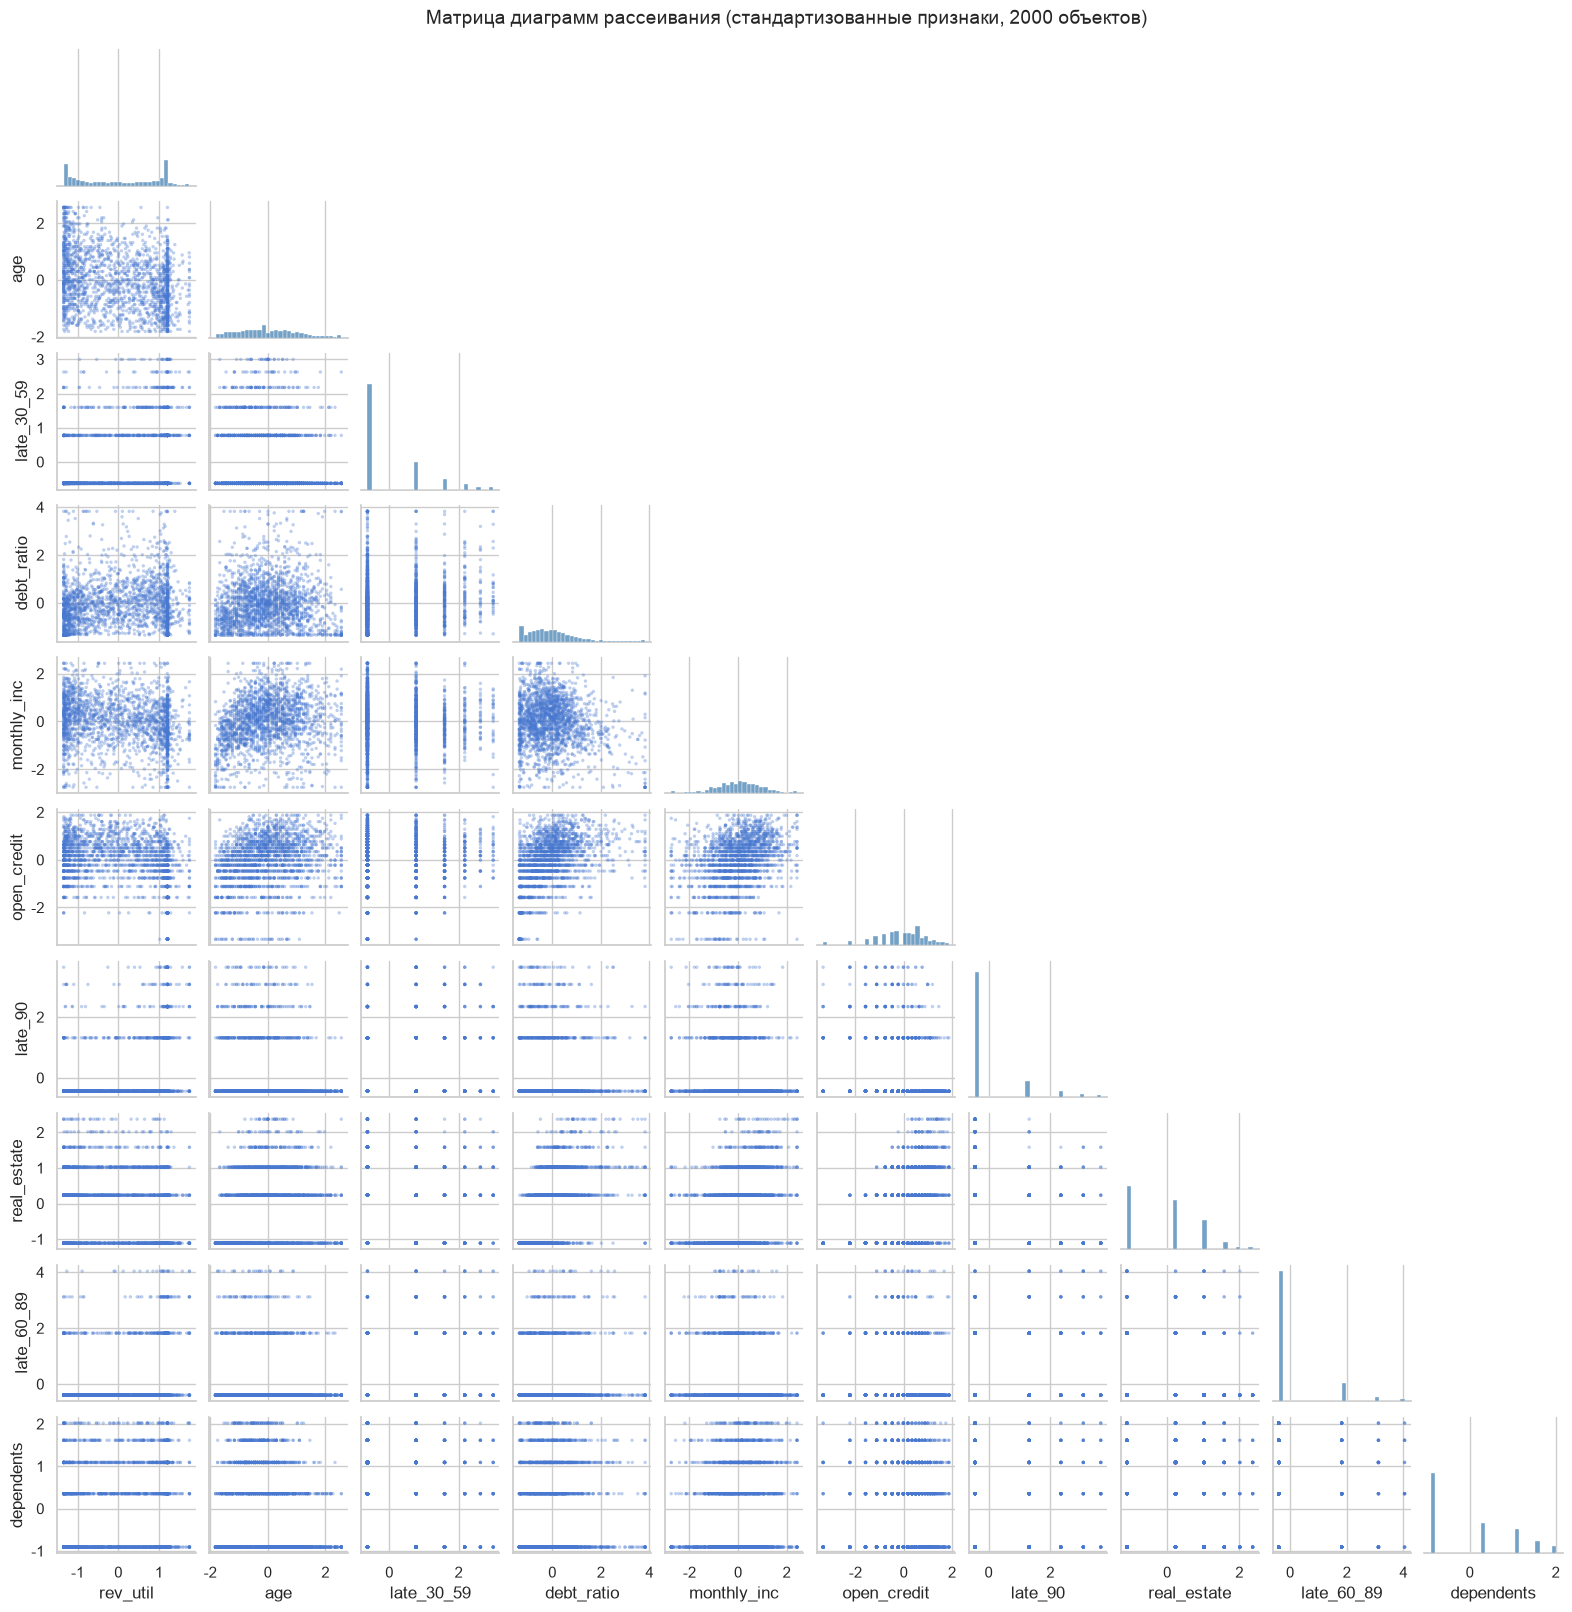

In [11]:
pp_sample = Zdf.sample(2000, random_state=SEED)
g = sns.pairplot(pp_sample, corner=True, plot_kws=dict(s=6, alpha=0.35, edgecolor="none"),
                 diag_kws=dict(bins=30, color="steelblue"), height=1.6)
g.fig.suptitle("Матрица диаграмм рассеивания (стандартизованные признаки, 2000 объектов)", y=1.01, fontsize=14)
plt.show()

**Пояснение к матрице рассеивания.**

* **Форма структуры.** Чётко отделённых сгустков нет. Облака точек сплошные, с плавно меняющейся плотностью. Видимую «полосатость» создают дискретные признаки (просрочки, кредиты, иждивенцы): точки выстраиваются вдоль уровней 0, 1, 2…
* **Предположительное число кластеров — 2–3.** Самое заметное разделение даёт наличие или отсутствие просрочек: на всех диаграммах с `late_*` выделяется плотная полоса z ≈ −0.5 (просрочек нет) и разреженная область при z > 1. Второй сигнал — **бимодальность `rev_util`**: на диагонали видны два пика, у z ≈ −1.3 (картами почти не пользуются) и у z ≈ +1.2 (лимит исчерпан почти полностью). В парах `open_credit` / `real_estate` / `age` / `rev_util` видно второе направление неоднородности: молодые клиенты с малым числом кредитов и высокой загрузкой лимитов против зрелых клиентов с ипотекой и низкой загрузкой.
* **Тип кластерной структуры:** перекрывающиеся выпуклые (эллипсоидальные) группы разного размера и плотности, без цепочек и вложенных невыпуклых форм.

### 3.4. Обоснование выбора методов кластеризации

| Метод | Соответствие данным | Решение |
|---|---|---|
| **K-means** | Ищет выпуклые компактные кластеры примерно одинакового разброса. Это соответствует наблюдаемым эллипсоидальным перекрывающимся группам. Быстрый (16 тыс. объектов), даёт центры, которые удобно интерпретировать как «портреты». | **основной метод №1** |
| **Иерархическая (Ward)** | Метод Уорда на каждом шаге объединяет кластеры с минимальным приростом внутрикластерной дисперсии, то есть оптимизирует тот же критерий, что K-means, но жадно и без случайной инициализации. Даёт дендрограмму для выбора k и показывает вложенность групп. При n ≈ 16 тыс. матрица расстояний (~1 ГБ) ещё помещается в память. | **основной метод №2** |
| **DBSCAN** | Предназначен для невыпуклых кластеров одинаковой плотности, разделённых разреженными областями. Здесь плотность меняется плавно и разрывов нет, поэтому ожидается вырождение (один кластер или много шума). | исследуется только в п. 4.4 как контрольный эксперимент |
| **GMM** | Подходит для перекрывающихся эллипсоидов, но предполагает гауссовость признаков. Счётчики с 70–85% нулей этому не соответствуют. | не используется |

Оба основных метода опираются на евклидову геометрию и сумму квадратов. Это делает их сравнение корректным: различия в результатах объясняются стратегией поиска (итеративная оптимизация против жадного объединения), а не разными критериями.

## 4. Ход работы

### 4.1. Подбор оптимального числа кластеров для K-means

Для k = 2…10 обучаем `KMeans(n_init=10)` и считаем:

* **WCSS (inertia)** — внутрикластерную сумму квадратов (метод локтя). «Локоть» определяем визуально и формально методом Kneedle (точка максимального отклонения нормированной кривой от хорды).
* **Средний коэффициент силуэта** s = (b − a) / max(a, b) ∈ [−1, 1], где a — среднее расстояние до своего кластера, b — до ближайшего чужого.
* **Индекс Калинского–Харабаза** (отношение межкластерной дисперсии к внутрикластерной, ↑) и **индекс Дэвиса–Болдина** (среднее «худшее» отношение разброса к расстоянию между центрами, ↓).

In [12]:
K_RANGE = range(2, 11)
km_rows = []
km_models = {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    km_models[k] = km
    km_rows.append({
        "k": k, "WCSS (inertia)": km.inertia_,
        "silhouette": silhouette_score(Z, km.labels_),
        "Calinski–Harabasz": calinski_harabasz_score(Z, km.labels_),
        "Davies–Bouldin": davies_bouldin_score(Z, km.labels_),
        "мин. размер кластера": np.bincount(km.labels_).min(),
    })
km_sel = pd.DataFrame(km_rows).set_index("k")

# «локоть» формально: точка максимального отклонения кривой WCSS от хорды (метод Kneedle)
w = km_sel["WCSS (inertia)"].values
ks = np.array(list(K_RANGE))
xn = (ks - ks.min()) / (ks.max() - ks.min())
yn = (w - w.min()) / (w.max() - w.min())
elbow_k = int(ks[np.argmax((1 - xn) - yn)])
km_sel["снижение WCSS, %"] = (-km_sel["WCSS (inertia)"].pct_change() * 100).round(1)
display(km_sel)
print("Локоть (Kneedle):", elbow_k,
      "| максимум silhouette:", km_sel["silhouette"].idxmax(),
      "| максимум CH:", km_sel["Calinski–Harabasz"].idxmax(),
      "| минимум DB:", km_sel["Davies–Bouldin"].idxmin())

,WCSS (inertia),silhouette,Calinski–Harabasz,Davies–Bouldin,мин. размер кластера,"снижение WCSS, %"
k,,,,,,
2,134551.526,0.204,3464.428,2.060,5833,NaN
3,118130.457,0.177,3106.501,1.847,2625,12.2
4,107108.361,0.144,2843.410,1.822,2057,9.3
5,99779.226,0.145,2588.531,1.803,1940,6.8
6,93708.785,0.148,2416.119,1.825,1520,6.1
7,88870.434,0.149,2270.868,1.716,1387,5.2
8,84553.167,0.141,2164.650,1.717,1347,4.9
9,81645.176,0.135,2033.999,1.745,1215,3.4
10,78991.877,0.138,1929.460,1.804,825,3.2


Локоть (Kneedle): 5 | максимум silhouette: 2 | максимум CH: 2 | минимум DB: 7


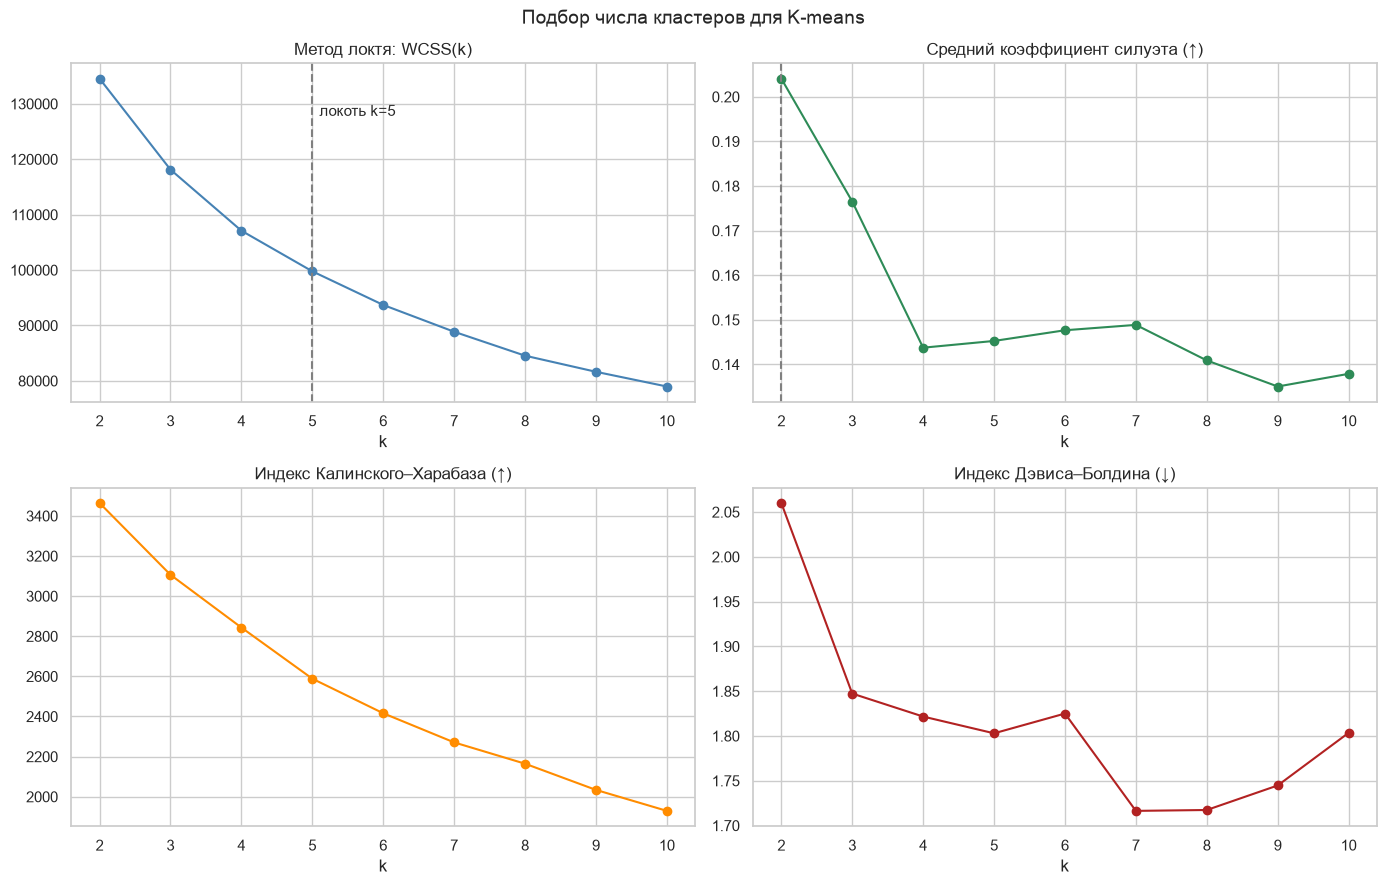

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [("WCSS (inertia)", "Метод локтя: WCSS(k)", "steelblue"),
         ("silhouette", "Средний коэффициент силуэта (↑)", "seagreen"),
         ("Calinski–Harabasz", "Индекс Калинского–Харабаза (↑)", "darkorange"),
         ("Davies–Bouldin", "Индекс Дэвиса–Болдина (↓)", "firebrick")]
for ax, (col, title, color) in zip(axes.ravel(), plots):
    ax.plot(km_sel.index, km_sel[col], "o-", color=color)
    ax.set_title(title); ax.set_xlabel("k"); ax.set_xticks(list(K_RANGE))
axes[0, 0].axvline(elbow_k, ls="--", color="grey"); axes[0, 0].text(elbow_k + 0.1, w.max() * 0.95, f"локоть k={elbow_k}")
axes[0, 1].axvline(km_sel["silhouette"].idxmax(), ls="--", color="grey")
fig.suptitle("Подбор числа кластеров для K-means", fontsize=14)
plt.tight_layout()
plt.show()

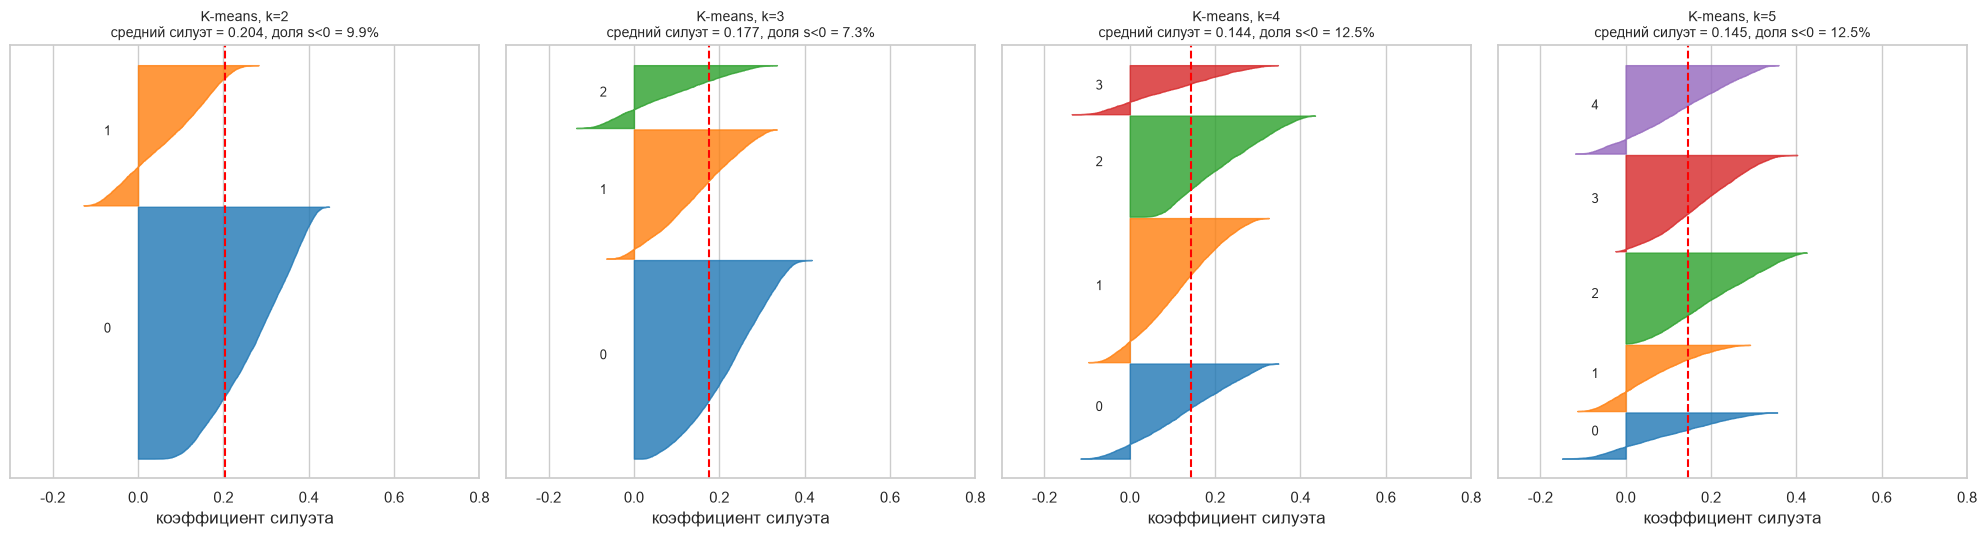

In [14]:
def silhouette_plot(ax, A, labels, title):
    s = silhouette_samples(A, labels)
    y_low = 10
    palette = sns.color_palette("tab10")
    for c in np.unique(labels):
        sc = np.sort(s[labels == c])
        ax.fill_betweenx(np.arange(y_low, y_low + len(sc)), 0, sc, color=palette[c % 10], alpha=0.8)
        ax.text(-0.08, y_low + len(sc) / 2, str(c), fontsize=9)
        y_low += len(sc) + 60
    ax.axvline(s.mean(), color="red", ls="--")
    ax.set_title(f"{title}\nсредний силуэт = {s.mean():.3f}, доля s<0 = {(s < 0).mean():.1%}", fontsize=10)
    ax.set_yticks([]); ax.set_xlabel("коэффициент силуэта"); ax.set_xlim(-0.3, 0.8)

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
for ax, k in zip(axes, [2, 3, 4, 5]):
    silhouette_plot(ax, Z, km_models[k].labels_, f"K-means, k={k}")
plt.tight_layout()
plt.show()

**Пояснение к выбору k.**

* **Метод локтя.** WCSS убывает монотонно и плавно: −12.2% при переходе 2→3, −9.3% при 3→4, −6.8% при 4→5, дальше по 3–6%. Kneedle формально указывает k = 5, но выраженного «локтя» нет. Это типично для данных без чётко разделённых кластеров, поэтому метод локтя здесь неоднозначен.
* **Силуэт** максимален при k = 2 (0.204), при k = 3 он равен 0.177, при k ≥ 4 падает до 0.14–0.15 и больше не растёт. **Калинский–Харабаз** тоже максимален при k = 2 (3 464) и монотонно убывает. **Дэвис–Болдин**, наоборот, при k = 2 худший (2.06) и заметно улучшается при k = 3 (1.85).
* **Силуэтные диаграммы.** При k = 2 и k = 3 самый крупный («благополучный») кластер не содержит объектов с s < 0, и его средний силуэт заметно выше общего (0.28 и 0.23). Отрицательные силуэты (~30%) сосредоточены в одном размытом кластере — «проблемных» заёмщиков. При k ≥ 4 отрицательные силуэты (15–29%) появляются уже в 2–3 кластерах, и средние значения кластеров опускаются до 0.06–0.13, то есть новые границы проводятся по однородной области и становятся искусственными.
* **Выбор: k = 3.**
  * Силуэт при k = 3 (0.177) лишь немного ниже максимума, а DB существенно лучше, чем при k = 2.
  * Дендрограмма Уорда (п. 4.2) показывает два крупных скачка высот: при 1→2 и 2→3 кластерах. После k = 3 скачки резко уменьшаются.
  * При k = 2 разбиение содержательно сводится к делению «есть просрочки / нет просрочек». При k = 3 «благополучная» часть делится ещё на две содержательно разные группы (п. 5), что ценно для сегментации.

Абсолютные значения силуэта (0.15–0.20) говорят о **слабой, перекрывающейся кластерной структуре**. Это согласуется со статистикой Хопкинса и матрицей рассеивания.

### 4.2. Иерархическая кластеризация: дендрограмма и выбор числа кластеров

Агломеративная кластеризация с метрикой Уорда построена на всех 16 313 объектах (`scipy.cluster.hierarchy.linkage`). Для читаемости дендрограмма обрезана до последних 30 объединений, в скобках указано число объектов в ветви.

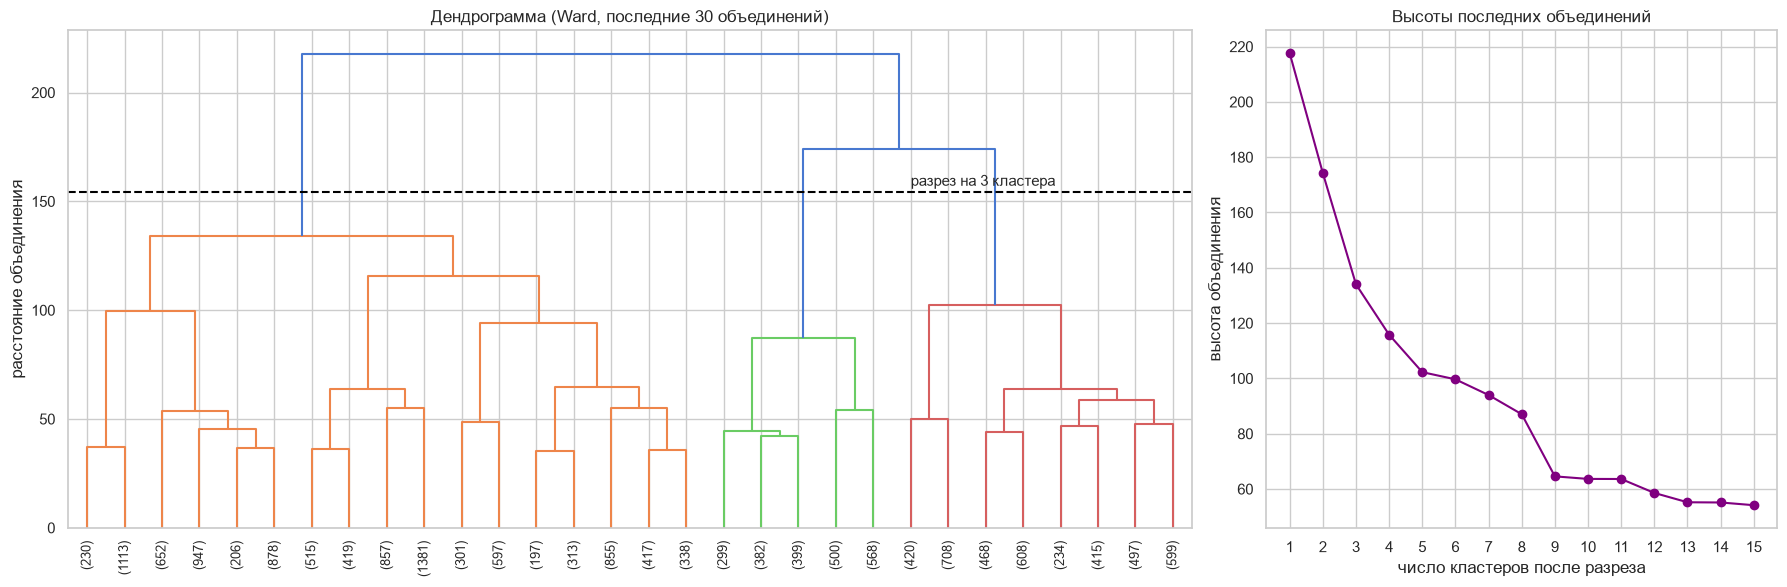

,высота слияния в k кластеров,скачок до k+1
k,,
1,217.639,43.373
2,174.267,40.249
3,134.018,18.226
4,115.792,13.532
5,102.261,2.598
6,99.663,5.676
7,93.987,6.938
8,87.049,22.476
9,64.573,0.921


,silhouette,Calinski–Harabasz,Davies–Bouldin,размеры кластеров
k,,,,
2,0.174,2770.245,2.312,"[10216, 6097]"
3,0.172,2550.802,1.911,"[10216, 3949, 2148]"
4,0.105,2256.384,2.105,"[6190, 4026, 3949, 2148]"
5,0.094,2048.391,2.002,"[4026, 3949, 3172, 3018, 2148]"
6,0.094,1886.514,2.016,"[4026, 3172, 3018, 2821, 2148, 1128]"
7,0.090,1788.540,1.978,"[3172, 3018, 2821, 2683, 2148, 1343, 1128]"
8,0.100,1714.480,1.878,"[3172, 2821, 2683, 2148, 2120, 1343, 1128, 898]"
9,0.107,1648.728,1.946,"[3172, 2821, 2683, 2120, 1343, 1128, 1080, 106..."
10,0.110,1542.999,1.942,"[3172, 2821, 2683, 1610, 1343, 1128, 1080, 106..."


In [15]:
LINK = linkage(Z, method="ward")          # иерархическая агломеративная кластеризация, метрика Уорда
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(LINK, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=9, color_threshold=LINK[-2, 2], ax=axes[0])
cut = (LINK[-2, 2] + LINK[-3, 2]) / 2
axes[0].axhline(cut, ls="--", color="black")
axes[0].text(axes[0].get_xlim()[1] * 0.75, cut + 3, "разрез на 3 кластера")
axes[0].set_title("Дендрограмма (Ward, последние 30 объединений)")
axes[0].set_ylabel("расстояние объединения")
heights = LINK[::-1, 2][:15]
axes[1].plot(range(1, 16), heights, "o-", color="purple")
axes[1].set_xticks(range(1, 16))
axes[1].set_xlabel("число кластеров после разреза")
axes[1].set_ylabel("высота объединения")
axes[1].set_title("Высоты последних объединений")
plt.tight_layout()
plt.show()
gaps = pd.DataFrame({"k": range(1, 15), "высота слияния в k кластеров": heights[:14],
                     "скачок до k+1": -np.diff(heights)})
display(gaps.head(9).set_index("k"))

hc_rows = []
for k in K_RANGE:
    lab = fcluster(LINK, k, criterion="maxclust") - 1
    hc_rows.append({"k": k, "silhouette": silhouette_score(Z, lab),
                    "Calinski–Harabasz": calinski_harabasz_score(Z, lab),
                    "Davies–Bouldin": davies_bouldin_score(Z, lab),
                    "размеры кластеров": sorted(np.bincount(lab).tolist(), reverse=True)})
hc_sel = pd.DataFrame(hc_rows).set_index("k")
display(hc_sel)

**Пояснение к дендрограмме.**

* Самые высокие объединения: 217.6 (2→1 кластер), 174.3 (3→2) и 134.0 (4→3). Скачки высот между соседними уровнями — **43.4, 40.2, затем 18.2, 13.5** и ниже. По правилу «резать там, где после разреза расстояния объединения резко уменьшаются» разумны **k = 2 или k = 3**. Разрез на уровне ~150 (пунктир) даёт 3 ветви: крупную (оранжевую, 10 216 объектов) и две меньшие (3 949 и 2 148).
* Следующий заметный скачок (22.5) приходится на k = 9. Мелкое разбиение плохо интерпретируется и даёт низкий силуэт (0.11).
* **Силуэт Уорда:** 0.174 (k = 2), 0.172 (k = 3), затем резкое падение до 0.105 при k = 4. CH убывает с ростом k, DB лучший при k = 3 (1.91). **Итог: для иерархической кластеризации тоже выбираем k = 3.** Решение по двум методам согласовано.

### 4.3. Обучение двух методов и расчёт метрик качества

**Параметры:**

* `KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)`. 10 инициализаций защищают от локальных минимумов (см. п. 4.4: с `n_init=1` результат нестабилен).
* `AgglomerativeClustering(n_clusters=3, linkage="ward")` — евклидова метрика (единственная допустимая для Уорда).

Номера кластеров в обоих методах упорядочены по возрастанию доли просрочек (C0 — наименее рискованный). Это нужно только для удобства сравнения, на качество не влияет.

In [16]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)

# Перенумеруем кластеры по возрастанию доли просрочек — чтобы номера в обоих методах были сопоставимы
def relabel_by_risk(labels):
    order = pd.Series(y).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.vectorize(mapping.get)(labels)

lab_km = relabel_by_risk(km.labels_)
lab_hc = relabel_by_risk(hc.labels_)
print("Размеры кластеров K-means:", np.bincount(lab_km))
print("Размеры кластеров Ward   :", np.bincount(lab_hc))
print("Совпадение c fcluster(scipy):", adjusted_rand_score(lab_hc, fcluster(LINK, K, "maxclust")))

Размеры кластеров K-means: [8293 5395 2625]
Размеры кластеров Ward   : [10216  3949  2148]
Совпадение c fcluster(scipy): 1.0


In [17]:
def centers_of(A, labels):
    return np.vstack([A[labels == c].mean(axis=0) for c in np.unique(labels)])

def geometry(A, labels):
    C = centers_of(A, labels)
    intra = [np.linalg.norm(A[labels == c] - C[c], axis=1) for c in range(len(C))]
    D = cdist(C, C)
    np.fill_diagonal(D, np.nan)
    return C, intra, D

def pair_jaccard(a, b):
    (tn, fp), (fn, tp) = pair_confusion_matrix(a, b)
    return tp / (tp + fp + fn)

def all_metrics(A, labels, y_true):
    C, intra, D = geometry(A, labels)
    h, c, v = homogeneity_completeness_v_measure(y_true, labels)
    mean_intra = np.mean([d.mean() for d in intra])
    return {
        "число кластеров": len(C),
        "silhouette (↑)": silhouette_score(A, labels),
        "Calinski–Harabasz (↑)": calinski_harabasz_score(A, labels),
        "Davies–Bouldin (↓)": davies_bouldin_score(A, labels),
        "WCSS": sum(((A[labels == k] - C[k]) ** 2).sum() for k in range(len(C))),
        "ср. расстояние до центра": mean_intra,
        "мин. расстояние между центрами": np.nanmin(D),
        "ср. расстояние между центрами": np.nanmean(D),
        "отношение межкл./внутрикл.": np.nanmin(D) / mean_intra,
        "Rand index (↑)": rand_score(y_true, labels),
        "Adjusted Rand (↑)": adjusted_rand_score(y_true, labels),
        "Jaccard (пары, ↑)": pair_jaccard(y_true, labels),
        "Fowlkes–Mallows (↑)": fowlkes_mallows_score(y_true, labels),
        "NMI (↑)": normalized_mutual_info_score(y_true, labels),
        "однородность": h, "полнота": c, "V-мера": v,
    }

metrics = pd.DataFrame({"K-means (k=3)": all_metrics(Z, lab_km, y),
                        "Иерархическая Ward (k=3)": all_metrics(Z, lab_hc, y)})
# опорные значения: случайное разбиение с теми же размерами кластеров
rng = np.random.default_rng(SEED)
metrics["случайные метки (размеры как у K-means)"] = pd.Series(all_metrics(Z, rng.permutation(lab_km), y))
display(metrics.style.format("{:.3f}"))

,K-means (k=3),Иерархическая Ward (k=3),случайные метки (размеры как у K-means)
число кластеров,3.000,3.000,3.000
silhouette (↑),0.177,0.172,-0.003
Calinski–Harabasz (↑),3106.501,2550.802,0.788
Davies–Bouldin (↓),1.847,1.911,260.330
WCSS,118130.360,124262.076,163114.241
ср. расстояние до центра,2.737,2.782,3.027
мин. расстояние между центрами,2.637,2.617,0.017
ср. расстояние между центрами,3.148,3.132,0.060
отношение межкл./внутрикл.,0.963,0.941,0.006
Rand index (↑),0.535,0.546,0.500


**Пояснение к метрикам.** Для сравнения добавлен столбец «случайные метки». Это то же распределение размеров, что у K-means, но с перемешанными метками, то есть уровень «отсутствия структуры».

*Внутренние метрики (без учёта класса):*

| Метрика | K-means | Ward | Интерпретация |
|---|---|---|---|
| Silhouette | **0.177** | 0.172 | Структура слабая, но реальная: у случайных меток −0.003. Объекты в среднем немного ближе к своему кластеру, чем к соседнему. |
| Calinski–Harabasz | **3 107** | 2 551 | Межкластерная дисперсия в тысячи раз больше, чем при случайном разбиении (0.8). K-means лучше, так как напрямую минимизирует WCSS. |
| Davies–Bouldin | **1.85** | 1.91 | Значение > 1: разброс кластеров сопоставим с расстоянием между центрами, кластеры перекрываются. |
| WCSS | **118 130** | 124 262 | K-means компактнее на 5%. Жадная процедура Уорда не может «переобъединить» объекты после неудачного раннего слияния. |

*Геометрия:* среднее расстояние объекта до центра ≈ 2.7–2.8, минимальное расстояние между центрами ≈ 2.6. **Отношение межкластерного расстояния к внутрикластерному ≈ 0.95–0.96 < 1**: центры соседних кластеров лежат ближе, чем «типичный радиус» кластера. Это количественное подтверждение перекрытия.

*Внешние метрики (относительно `dlq_2yrs`, по 2 класса против 3 кластеров):*

| Метрика | K-means | Ward | Случайно | Интерпретация |
|---|---|---|---|---|
| Rand index | 0.535 | **0.546** | 0.500 | Доля пар объектов, по которым кластеризация и класс «согласны». Умеренно выше случайного уровня. |
| Adjusted Rand | 0.071 | **0.092** | 0.000 | С поправкой на случайность согласие слабое, но положительное. |
| Jaccard (пары) | 0.316 | **0.362** | 0.282 | Доля пар «вместе в классе и в кластере» среди пар, объединённых хотя бы одним разбиением. |
| NMI / V-мера | 0.103 | 0.103 | 0 | Кластеры несут ~10% информации о классе. |
| Однородность / полнота | 0.126 / 0.087 | 0.119 / 0.091 | 0 | Кластеры однородны по классу лишь частично. Полнота низкая, потому что неплатёжеспособные заёмщики попадают во все кластеры. |

Низкие ARI и NMI **не означают плохую кластеризацию**. Кластеры описывают *поведенческие сегменты*, а не бинарный исход «просрочка / нет». Класс в датасете определён по одному признаку (просрочка 90+ за 2 года), а алгоритм группирует по всем 10 признакам. При этом связь с риском выражена очень сильно (п. 4.3.2): в одном из кластеров доля просрочек 90–93%.

#### 4.3.1. Центры, внутрикластерные и межкластерные расстояния

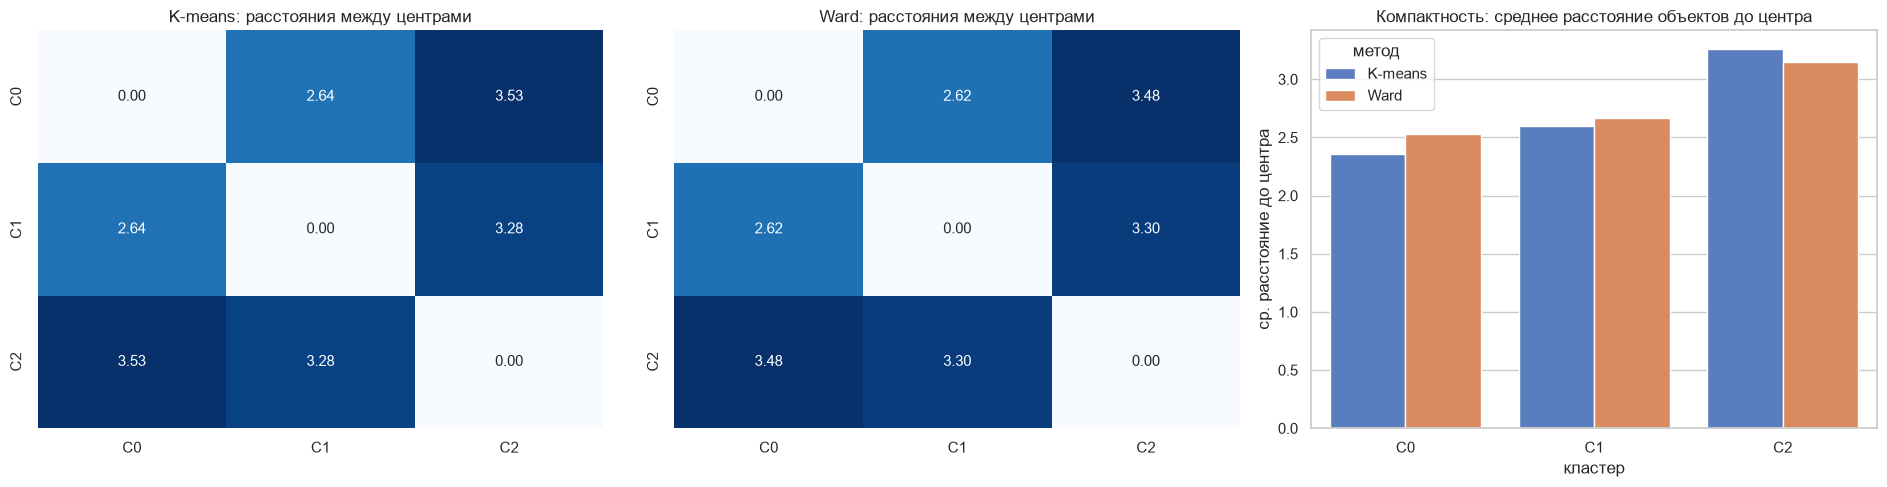

размер  ср. расстояние до центра  медиана  радиус (95%)  ближайший другой центр
метод   кластер                                                                                 
K-means C0         8293                     2.359    2.246         3.703                   2.637
        C1         5395                     2.596    2.520         3.777                   2.637
        C2         2625                     3.257    3.245         4.398                   3.280
Ward    C0        10216                     2.531    2.408         4.024                   2.617
        C1         3949                     2.669    2.591         3.946                   2.617
        C2         2148                     3.146    3.092         4.371                   3.304

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, lab) in zip(axes[:2], [("K-means", lab_km), ("Ward", lab_hc)]):
    C, intra, D = geometry(Z, lab)
    Dshow = cdist(C, C)
    sns.heatmap(Dshow, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar=False,
                xticklabels=[f"C{i}" for i in range(K)], yticklabels=[f"C{i}" for i in range(K)])
    ax.set_title(f"{name}: расстояния между центрами")
geo = []
for name, lab in [("K-means", lab_km), ("Ward", lab_hc)]:
    C, intra, D = geometry(Z, lab)
    for c in range(K):
        geo.append({"метод": name, "кластер": f"C{c}", "размер": len(intra[c]),
                    "ср. расстояние до центра": intra[c].mean(),
                    "медиана": np.median(intra[c]), "радиус (95%)": np.quantile(intra[c], .95),
                    "ближайший другой центр": np.nanmin(D[c])})
geo = pd.DataFrame(geo)
sns.barplot(data=geo, x="кластер", y="ср. расстояние до центра", hue="метод", ax=axes[2])
axes[2].set_title("Компактность: среднее расстояние объектов до центра")
plt.tight_layout()
plt.show()
display(geo.set_index(["метод", "кластер"]))

**Пояснение к геометрии кластеров.**

* **Компактность.** Самый компактный кластер — C0, «благополучные» (среднее расстояние до центра 2.36 у K-means). Самый размытый — C2, «проблемные» (3.26 у K-means, 3.15 у Ward, радиус 95% ≈ 4.4). Это ожидаемо: заёмщики с просрочками сильно различаются по их числу, типу и долговой нагрузке, а благополучные клиенты однородны (нули во всех счётчиках просрочек).
* **Межкластерные расстояния.** Ближе всего друг к другу C0 и C1 (2.64 у K-means, 2.62 у Ward): оба кластера — заёмщики без систематических просрочек, отличающиеся «зрелостью». Кластер C2 удалён от обоих (≈ 3.3–3.6). Значит, **граница «есть просрочки / нет просрочек» выражена сильнее всего**, и именно её находит разбиение при k = 2.
* По размерам методы различаются: у K-means кластеры 8 293 / 5 395 / 2 625, у Ward — 10 216 / 3 949 / 2 148. Ward относит к «благополучному» кластеру больше пограничных объектов.

#### 4.3.2. Связь кластеров с известным классом

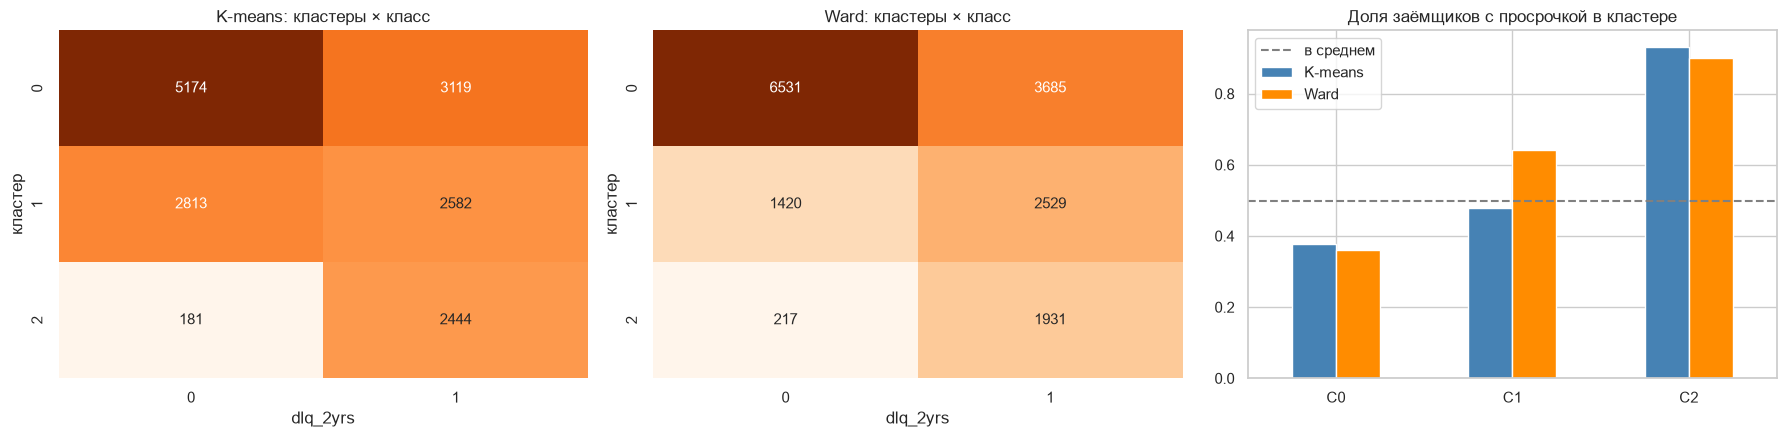

,K-means,Ward
кластер,,
C0,0.376,0.361
C1,0.479,0.640
C2,0.931,0.899


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, lab) in zip(axes[:2], [("K-means", lab_km), ("Ward", lab_hc)]):
    ct = pd.crosstab(pd.Series(lab, name="кластер"), pd.Series(y, name="dlq_2yrs"))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Oranges", ax=ax, cbar=False)
    ax.set_title(f"{name}: кластеры × класс")
risk = pd.DataFrame({"K-means": pd.Series(y).groupby(lab_km).mean(),
                     "Ward": pd.Series(y).groupby(lab_hc).mean()})
risk.index = [f"C{i}" for i in risk.index]
risk.plot.bar(ax=axes[2], rot=0, color=["steelblue", "darkorange"])
axes[2].axhline(y.mean(), ls="--", color="grey", label="в среднем")
axes[2].set_title("Доля заёмщиков с просрочкой в кластере"); axes[2].legend()
plt.tight_layout()
plt.show()
display(risk.rename_axis("кластер").style.format("{:.3f}"))

**Пояснение.**

* **Кластер C2 — заёмщики с высоким риском:** доля `dlq_2yrs = 1` составляет **93.1% (K-means) и 89.9% (Ward)** при среднем 50%. Оба метода независимо от класса выделили группу, в которой почти все заёмщики имели серьёзную просрочку.
* У C0 доля просрочек 37.6% / 36.1%, это заметно ниже среднего. У C1 — 47.9% (K-means) против 64.0% (Ward). Ward включает в C1 более «молодую» и сильнее закредитованную часть, поэтому его C1 рискованнее.
* Внешние метрики (ARI ≈ 0.07–0.09) низкие, потому что ~37% заёмщиков благополучного кластера C0 тоже имели просрочку. По 10 признакам они неотличимы от добросовестных клиентов. Для кредитного скоринга это известный эффект: часть дефолтов вызвана событиями, которых нет в данных (потеря работы, болезнь).

### 4.4. Влияние параметров на качество кластеризации

#### 4.4.1. K-means: число кластеров k, способ инициализации `init` и число запусков `n_init`

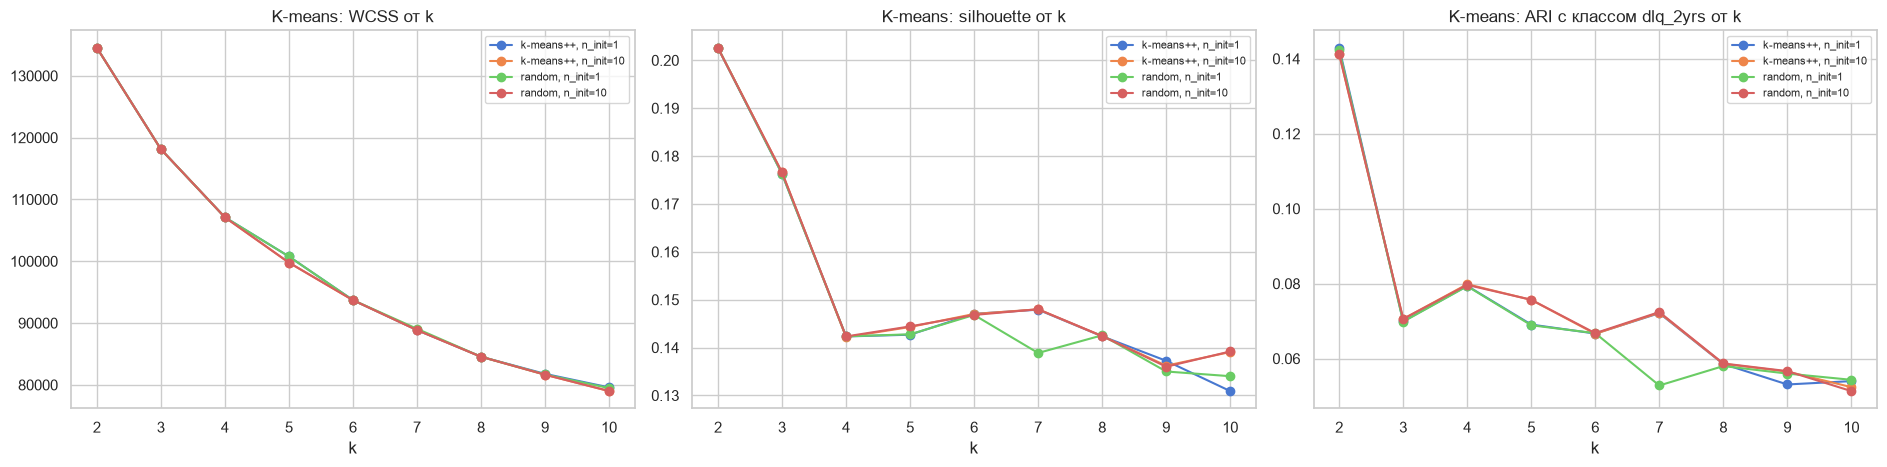

init   k-means++              random          
n_init        1         10        1         10
k                                             
2       134552.0  134552.0  134552.0  134552.0
3       118131.0  118130.0  118131.0  118130.0
4       107109.0  107108.0  107109.0  107109.0
5       100774.0   99779.0  100775.0   99779.0
6        93709.0   93709.0   93708.0   93708.0
7        88871.0   88870.0   89080.0   88870.0
8        84554.0   84553.0   84558.0   84553.0
9        81779.0   81645.0   81677.0   81645.0
10       79590.0   78992.0   79480.0   79006.0

In [20]:
rows = []
for k in K_RANGE:
    for init in ["k-means++", "random"]:
        for n_init in [1, 10]:
            m = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=SEED).fit(Z)
            rows.append({"k": k, "init": init, "n_init": n_init, "WCSS": m.inertia_, "итераций": m.n_iter_,
                         "silhouette": silhouette_score(Z, m.labels_, sample_size=8000, random_state=SEED),
                         "ARI с классом": adjusted_rand_score(y, m.labels_)})
grid = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for (init, n_init), g in grid.groupby(["init", "n_init"]):
    lbl = f"{init}, n_init={n_init}"
    axes[0].plot(g["k"], g["WCSS"], "o-", label=lbl)
    axes[1].plot(g["k"], g["silhouette"], "o-", label=lbl)
    axes[2].plot(g["k"], g["ARI с классом"], "o-", label=lbl)
for ax, t in zip(axes, ["WCSS", "silhouette", "ARI с классом dlq_2yrs"]):
    ax.set_title(f"K-means: {t} от k"); ax.set_xlabel("k"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(grid.pivot_table(index="k", columns=["init", "n_init"], values="WCSS").round(0))

In [21]:
# Устойчивость к начальной инициализации: 20 запусков с n_init=1 при разных seed
stab = []
for k in [2, 3, 4, 5, 6]:
    labs = [KMeans(n_clusters=k, n_init=1, init="random", random_state=s).fit(Z) for s in range(20)]
    inert = np.array([m.inertia_ for m in labs])
    ref = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z).labels_
    aris = [adjusted_rand_score(ref, m.labels_) for m in labs]
    stab.append({"k": k, "WCSS: мин": inert.min(), "WCSS: макс": inert.max(),
                 "разброс WCSS, %": (inert.max() - inert.min()) / inert.min() * 100,
                 "ARI с эталоном: среднее": np.mean(aris), "ARI: мин": np.min(aris)})
display(pd.DataFrame(stab).set_index("k"))

,WCSS: мин,WCSS: макс,"разброс WCSS, %",ARI с эталоном: среднее,ARI: мин
k,,,,,
2,134551.526,134552.420,6.646e-04,0.995,0.990
3,118130.357,120456.617,1.969e+00,0.852,0.412
4,107108.370,107111.565,2.984e-03,0.987,0.975
5,99778.893,100989.516,1.213e+00,0.856,0.546
6,93707.928,95051.076,1.433e+00,0.836,0.491


**Пояснение к параметрам K-means.**

* **Число кластеров k** — главный параметр.
  * С ростом k WCSS монотонно убывает (с 134.6 тыс. до 79.0 тыс. при k = 10). Это свойство целевой функции, а не признак улучшения разбиения.
  * Силуэт падает с 0.20 (k = 2) до ~0.14 и дальше выходит на плато.
  * **ARI с классом максимален при k = 2** (0.141): двухкластерное разбиение почти повторяет деление «есть просрочки / нет». При k = 3–7 ARI держится на уровне 0.07–0.08, при k ≥ 8 убывает до 0.05: новые кластеры дробят данные по признакам, не связанным с риском (возраст, иждивенцы, ипотека). Значит, k = 3 выбран ради более подробной сегментации, а не ради совпадения с классом.
* **`init` (k-means++ или random)** при `n_init = 10` почти не влияет: итоговые WCSS совпадают до единиц. При одном запуске (`n_init = 1`) обе схемы иногда останавливаются в худшем локальном минимуме: при k = 7 случайная инициализация даёт WCSS 89 080 против 88 871, а при k = 10 k-means++ даёт 79 590 и random 79 480 против 78 992 при `n_init = 10`. Систематического преимущества одной схемы на этих данных нет.
* **`n_init`** заметно влияет при k = 3, 5, 6, 9, 10. Здесь целевая функция многоэкстремальна:
  * В 20 одиночных запусках со случайной инициализацией при **k = 3** WCSS колеблется в пределах 2%, а согласие с эталонным разбиением падает **до ARI = 0.41**: часть запусков застревает в другом локальном минимуме и делит данные иначе.
  * При k = 2 и k = 4 решение устойчиво (ARI ≥ 0.97).
  * При `n_init = 1` и k = 5 итоговый WCSS на 1% хуже (100 774 против 99 779).

  **Вывод:** `n_init = 10` (рекомендация методички) необходим. Он гарантирует, что результат не зависит от случайного начального приближения.

In [22]:
link_rows = []
for method in ["ward", "complete", "average", "single"]:
    L = LINK if method == "ward" else linkage(Z, method=method)
    for k in [2, 3, 4, 5]:
        lab = fcluster(L, k, criterion="maxclust") - 1
        link_rows.append({"связь": method, "k": k,
                          "silhouette": silhouette_score(Z, lab, sample_size=8000, random_state=SEED),
                          "ARI с классом": adjusted_rand_score(y, lab),
                          "размеры кластеров": sorted(np.bincount(lab).tolist(), reverse=True)})
display(pd.DataFrame(link_rows).set_index(["связь", "k"]))

silhouette  ARI с классом               размеры кластеров
связь    k                                                           
ward     2       0.173      1.207e-01                   [10216, 6097]
         3       0.172      9.214e-02             [10216, 3949, 2148]
         4       0.104      7.287e-02        [6190, 4026, 3949, 2148]
         5       0.095      9.369e-02  [4026, 3949, 3172, 3018, 2148]
complete 2       0.119      8.853e-03                   [14568, 1745]
         3       0.081      7.554e-03              [14568, 1123, 622]
         4       0.092      2.008e-02         [13919, 1123, 649, 622]
         5       0.090      9.394e-02    [9442, 4477, 1123, 649, 622]
average  2       0.321      1.454e-04                    [16213, 100]
         3       0.227      4.344e-02              [14220, 1993, 100]
         4       0.155      4.411e-02          [14191, 1993, 100, 29]
         5       0.132      4.408e-02       [14191, 1992, 100, 29, 1]
single   2       0.370      3.462e-07                      [16312, 1]
         3       0.370      7.074e-07                   [16311, 1, 1]
         4       0.334      1.084e-06                [16310, 1, 1, 1]
         5       0.325      6.934e-07             [16309, 1, 1, 1, 1]

#### 4.4.2. Иерархическая кластеризация: тип связи (linkage)

**Пояснение.** Тип связи определяет, как считается расстояние между кластерами, и радикально меняет результат.

* **Ward** — единственный вариант с **сбалансированными кластерами** (10 216 / 3 949 / 2 148) и максимальным согласием с классом (ARI = 0.12 при k = 2).
* **Single** (ближайший сосед) даёт формально самый высокий силуэт (0.37), но это артефакт: алгоритм отделяет **одиночные объекты** (16 312 + 1), а все остальные объекты соединяются в одну цепочку. Это «эффект цепочки», типичный для данных без разрывов.
* **Average** ведёт себя похоже: [16 213, 100] при k = 2. Силуэт 0.32 возникает за счёт отделения сотни крайних объектов.
* **Complete** (дальний сосед) выделяет мелкие периферийные группы (1 745, 1 123, 622 объекта) и даёт низкий силуэт (0.08–0.12).

**Вывод:** при плавно меняющейся плотности без разрывов только метод Уорда находит содержательную структуру. Высокий силуэт сам по себе не гарантирует качество: его нужно проверять по размерам кластеров.

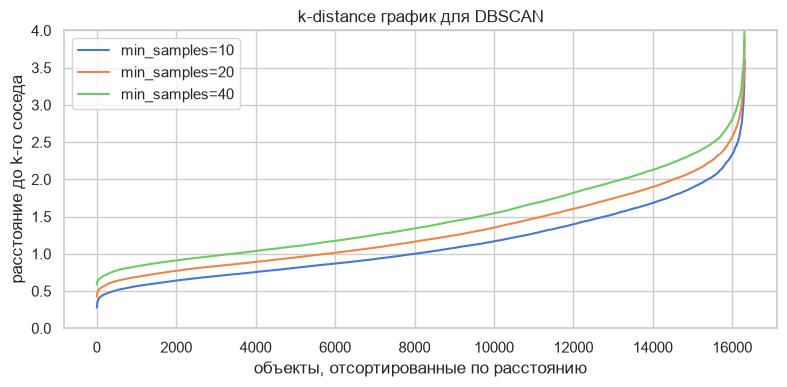

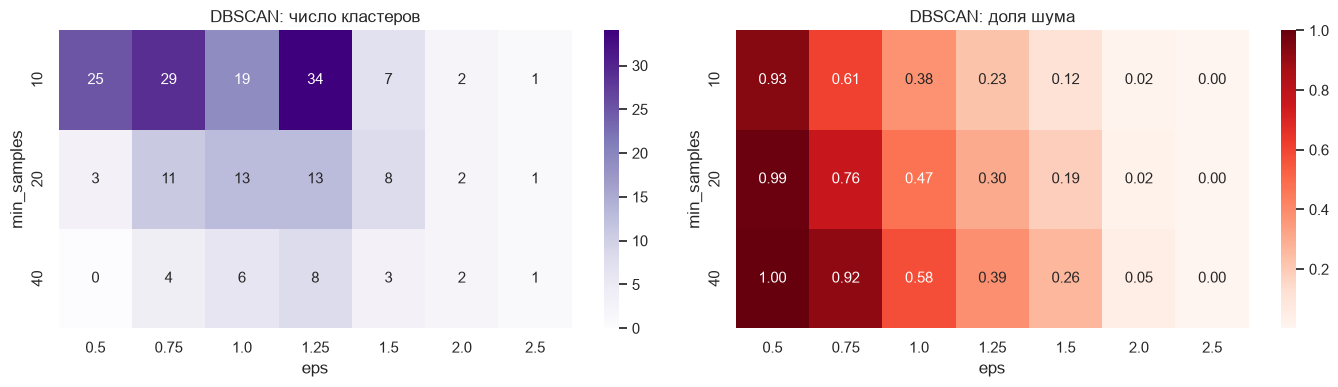

кластеров  доля шума  доля крупнейшего кластера  silhouette (без шума)
eps  min_samples                                                                        
0.50 10                  25      0.934                      0.025                  0.185
     20                   3      0.989                      0.004                  0.494
     40                   0      1.000                      0.000                    NaN
0.75 10                  29      0.613                      0.102                 -0.085
     20                  11      0.764                      0.081                 -0.005
     40                   4      0.921                      0.033                  0.234
1.00 10                  19      0.380                      0.178                  0.074
     20                  13      0.473                      0.165                  0.039
     40                   6      0.577                      0.145                  0.140
1.25 10                  34      0.226                      0.191                  0.078
     20                  13      0.304                      0.189                  0.122
     40                   8      0.386                      0.185                  0.104
1.50 10                   7      0.117                      0.736                  0.146
     20                   8      0.186                      0.727                 -0.036
     40                   3      0.264                      0.711                  0.222
2.00 10                   2      0.016                      0.850                  0.235
     20                   2      0.024                      0.848                  0.231
     40                   2      0.048                      0.844                  0.210
2.50 10                   1      0.002                      0.998                    NaN
     20                   1      0.003                      0.997                    NaN
     40                   1      0.004                      0.996                    NaN

In [23]:
# DBSCAN: k-distance график для выбора eps и сетка eps × min_samples
fig, ax = plt.subplots(figsize=(8, 4))
for ms in [10, 20, 40]:
    d = np.sort(NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1])
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 4); ax.set_xlabel("объекты, отсортированные по расстоянию"); ax.set_ylabel("расстояние до k-го соседа")
ax.set_title("k-distance график для DBSCAN"); ax.legend()
plt.tight_layout()
plt.show()

db_rows = []
for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]:
    for ms in [10, 20, 40]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        mask = lab != -1
        sil = silhouette_score(Z[mask], lab[mask], sample_size=min(8000, mask.sum()), random_state=SEED) \
            if n_cl >= 2 else np.nan
        sizes = np.bincount(lab[mask]) if mask.any() else np.array([0])
        db_rows.append({"eps": eps, "min_samples": ms, "кластеров": n_cl, "доля шума": 1 - mask.mean(),
                        "доля крупнейшего кластера": sizes.max() / len(lab), "silhouette (без шума)": sil})
db = pd.DataFrame(db_rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(db.pivot(index="min_samples", columns="eps", values="кластеров"), annot=True, fmt="d", cmap="Purples", ax=axes[0])
axes[0].set_title("DBSCAN: число кластеров")
sns.heatmap(db.pivot(index="min_samples", columns="eps", values="доля шума"), annot=True, fmt=".2f", cmap="Reds", ax=axes[1])
axes[1].set_title("DBSCAN: доля шума")
plt.tight_layout()
plt.show()
display(db.set_index(["eps", "min_samples"]))

#### 4.4.3. DBSCAN: радиус окрестности ε и min_samples (контрольный эксперимент)

**Пояснение.**

* На k-distance графике расстояние до k-го соседа растёт плавно и почти линейно (≈ 0.5 → 2.0 для 95% объектов). Резкий подъём есть только у последних ~2% точек (ε ≈ 2.5–3), то есть у периферийных объектов. Порога плотности, который отделял бы кластеры друг от друга, нет.
* **Малое ε (0.5–1.0):** большинство точек считается шумом (38–100%), а остаток дробится на десятки мелких «сгустков» (до 29 кластеров) из объектов с одинаковыми значениями дискретных признаков.
* **Среднее ε (1.25–1.5):** доля шума 12–39%, но один кластер уже поглощает 71–74% данных, а остальные — мелкие фрагменты.
* **Большое ε (2.0):** 2 кластера, один из них содержит **85%** объектов, шума 2–5%. При ε ≥ 2.5 остаётся 1 кластер (99.6–99.8% объектов).
* **Влияние min_samples:** при фиксированном ε увеличение min_samples повышает требования к плотности ядра. Растёт доля шума, а число кластеров обычно уменьшается (ε = 0.75: 29 → 11 → 4 кластера при min_samples = 10/20/40).

**Вывод:** DBSCAN не подходит для этих данных. Кластеры здесь не отделены зонами низкой плотности, поэтому плотностной метод либо объявляет большинство объектов шумом, либо сливает всё в один кластер. Это подтверждает правильность выбора K-means и Ward.

## 5. Визуализация результатов

### 5.1. Кластеры в пространстве главных компонент и в исходных признаках

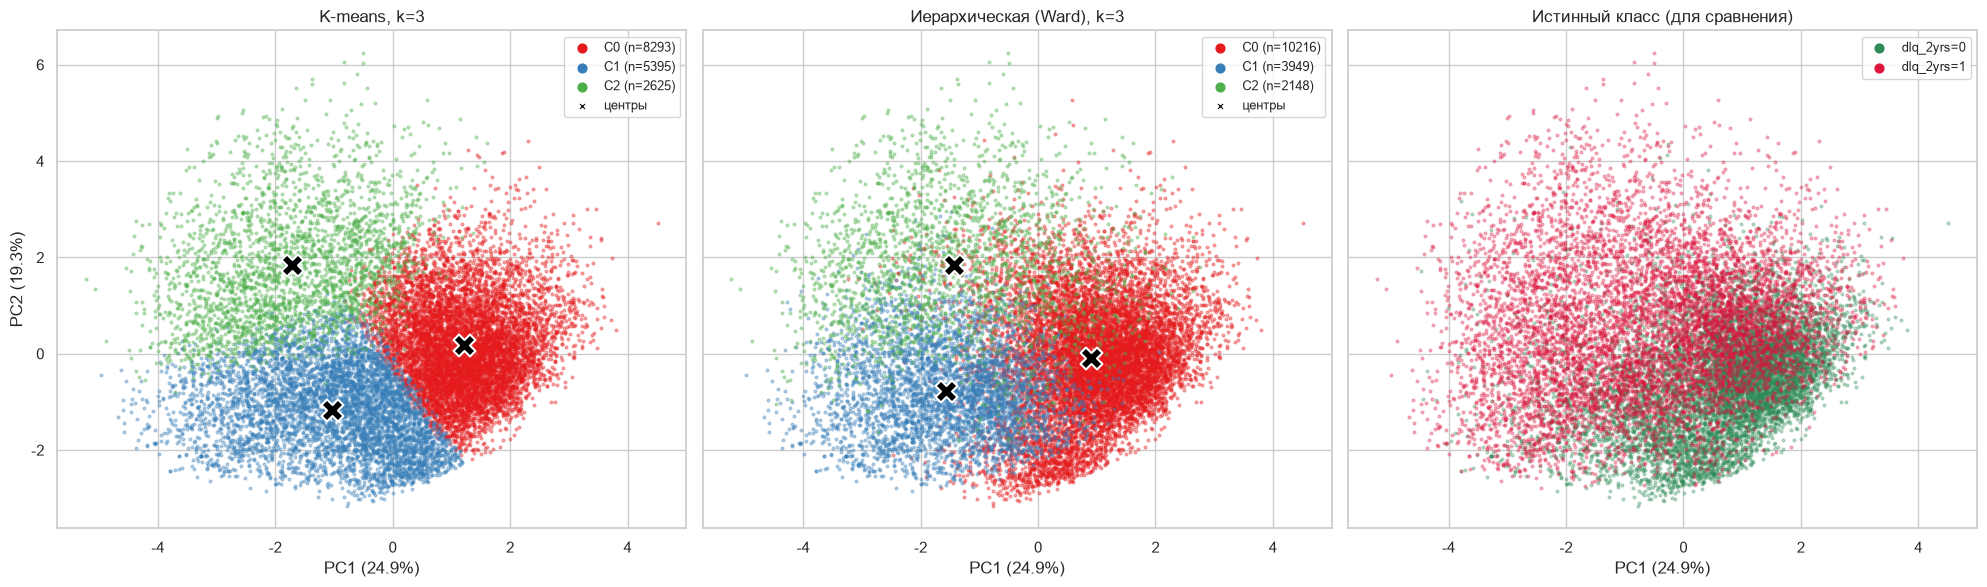

In [24]:
pca2 = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca2.transform(Z)
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)
pal = sns.color_palette("Set1", K)
for ax, (name, lab) in zip(axes[:2], [("K-means", lab_km), ("Иерархическая (Ward)", lab_hc)]):
    for c in range(K):
        m = lab == c
        ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.35, color=pal[c], label=f"C{c} (n={m.sum()})")
    Cp = pca2.transform(centers_of(Z, lab))
    ax.scatter(Cp[:, 0], Cp[:, 1], marker="X", s=250, c="black", edgecolor="white", linewidth=1.5, label="центры")
    ax.set_title(f"{name}, k={K}")
for cls, color in [(0, "seagreen"), (1, "crimson")]:
    m = y == cls
    axes[2].scatter(P[m, 0], P[m, 1], s=4, alpha=0.3, color=color, label=f"dlq_2yrs={cls}")
axes[2].set_title("Истинный класс (для сравнения)")
for ax in axes:
    leg = ax.legend(fontsize=9, loc="upper right")
    for h in leg.legend_handles:
        h.set_sizes([40]); h.set_alpha(1)
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

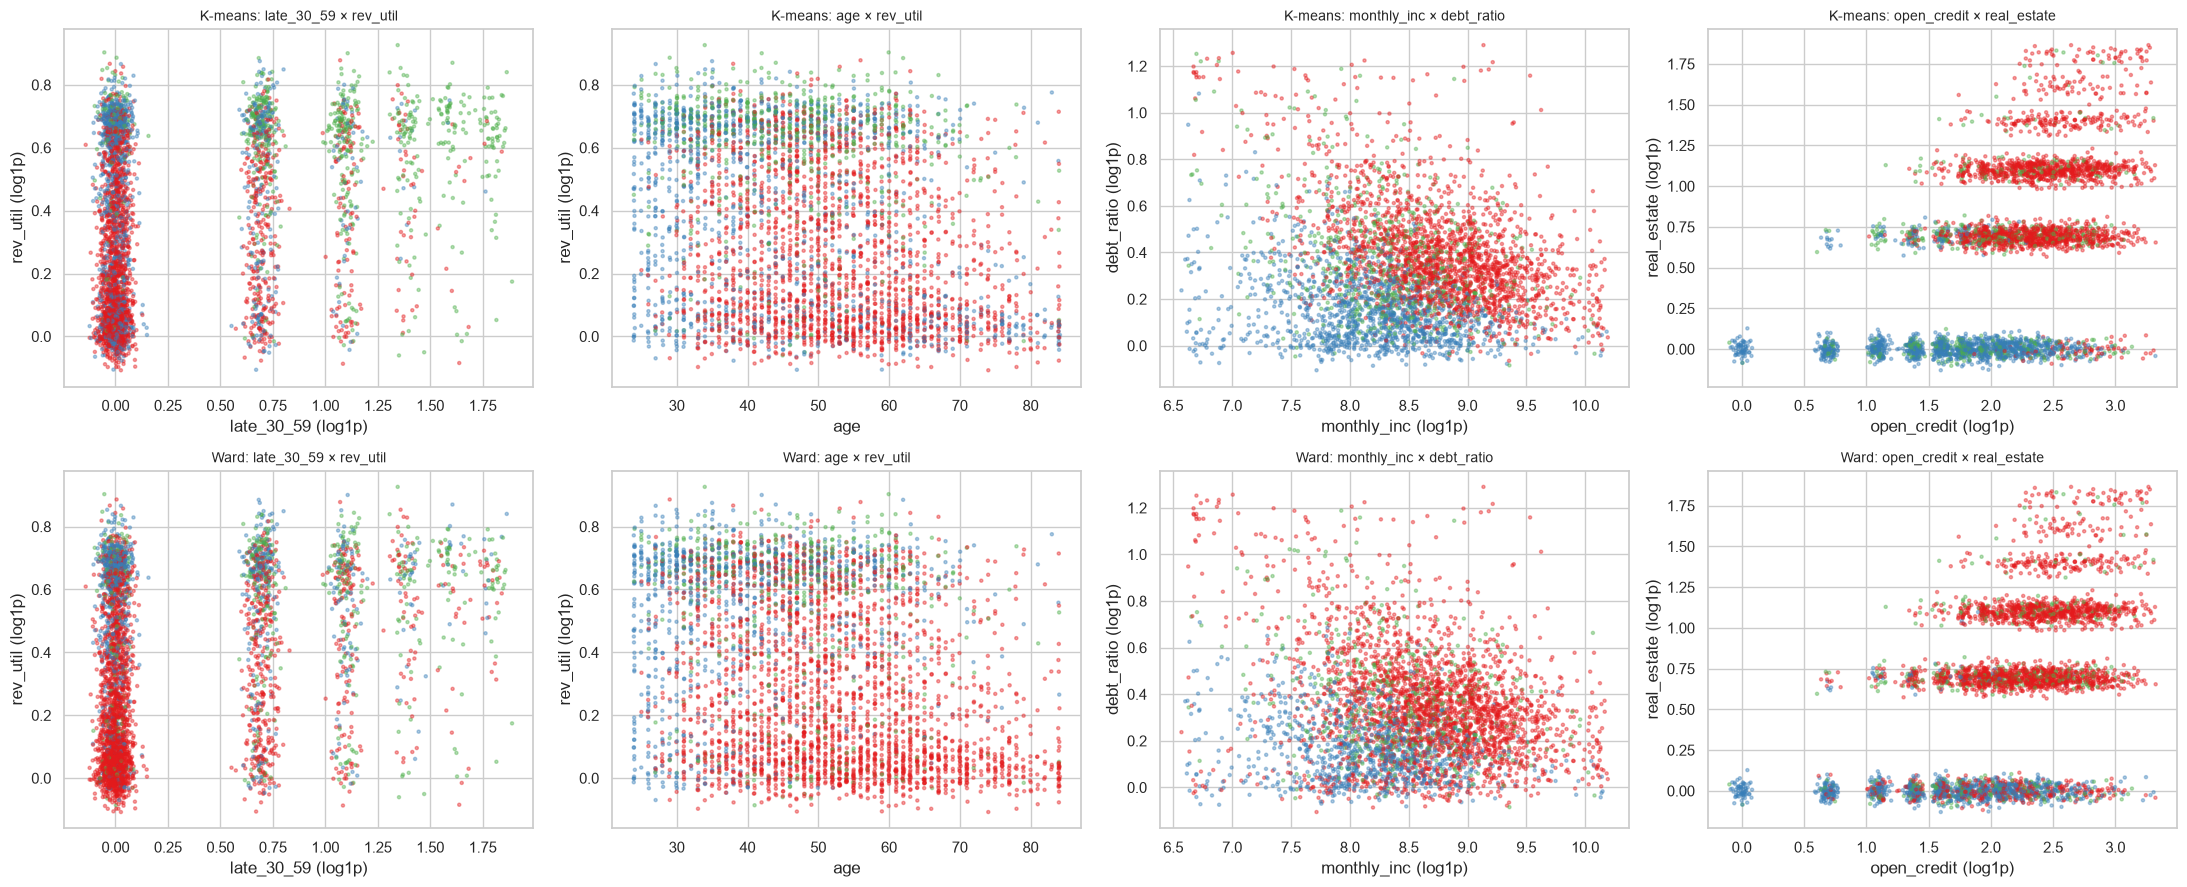

In [25]:
# Кластеры в исходных признаках: несколько наиболее «разделяющих» пар
pairs = [("late_30_59", "rev_util"), ("age", "rev_util"), ("monthly_inc", "debt_ratio"), ("open_credit", "real_estate")]
sample_idx = np.random.default_rng(SEED).choice(len(Z), 4000, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for row, (name, lab) in enumerate([("K-means", lab_km), ("Ward", lab_hc)]):
    for ax, (a, b) in zip(axes[row], pairs):
        jit = np.random.default_rng(1).normal(0, 0.04, size=(len(sample_idx), 2))
        ax.scatter(X_t[a].values[sample_idx] + jit[:, 0], X_t[b].values[sample_idx] + jit[:, 1],
                   c=[pal[c] for c in lab[sample_idx]], s=5, alpha=0.4)
        ax.set_xlabel(a + (" (log1p)" if a in LOG_COLS else "")); ax.set_ylabel(b + (" (log1p)" if b in LOG_COLS else ""))
        ax.set_title(f"{name}: {a} × {b}", fontsize=10)
plt.tight_layout()
plt.show()

**Пояснение к визуализации.**

* **В плоскости PC1–PC2** (44% дисперсии) у K-means три сектора с прямыми границами — это диаграмма Вороного относительно центров:
  * C0 (красный, справа) — высокий PC1, «зрелые» клиенты;
  * C1 (синий, слева внизу) — низкий PC1 и PC2;
  * C2 (зелёный, сверху) — высокий PC2, «проблемность».
* У **Ward** границы размыты, и кластеры C0/C1 сильнее перемешаны в проекции. Это следствие жадного объединения: часть объектов закрепляется в ветвях на ранних шагах.
* **Истинный класс** (правая панель) распределён диффузно: просрочки сконцентрированы сверху и слева (высокий PC2 / низкий PC1), но встречаются по всему облаку. Поэтому кластеры не могут совпасть с классами, а внешние метрики умеренные.
* **В исходных признаках** (после log1p) лучше всего разделение видно на `late_30_59 × rev_util`: кластер C2 занимает область ненулевых просрочек и высокой загрузки лимита. На `open_credit × real_estate` C0 занимает область «есть ипотека, много кредитов», а C1 — «нет ипотеки, мало кредитов».

### 5.2. Анализ центров и содержательная интерпретация кластеров

В таблицах — **медианы в исходных единицах** (без логарифма и стандартизации), их проще интерпретировать. На тепловой карте — центры в z-оценках (+ выше среднего по выборке, − ниже).

K-means: медианы признаков в исходных единицах


,размер,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,ср. число просрочек,доля без просрочек,доля dlq_2yrs=1
C0,8293.00,0.23,52.00,0.00,0.42,6500.00,10.00,0.00,2.00,0.00,1.00,0.43,0.73,0.38
C1,5395.00,0.59,42.00,0.00,0.13,3632.00,5.00,0.00,0.00,0.00,0.00,0.56,0.63,0.48
C2,2625.00,0.97,45.00,2.00,0.38,4223.00,6.00,1.00,1.00,1.00,1.00,4.64,0.00,0.93


Ward: медианы признаков в исходных единицах


,размер,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,ср. число просрочек,доля без просрочек,доля dlq_2yrs=1
C0,10216.00,0.20,52.00,0.00,0.38,5950.00,9.00,0.00,1.00,0.00,1.00,0.50,0.75,0.36
C1,3949.00,0.90,38.00,0.00,0.15,3500.00,4.00,0.00,0.00,0.00,0.00,1.13,0.46,0.64
C2,2148.00,0.91,47.00,1.00,0.38,4583.00,7.00,1.00,1.00,1.00,1.00,4.30,0.00,0.90


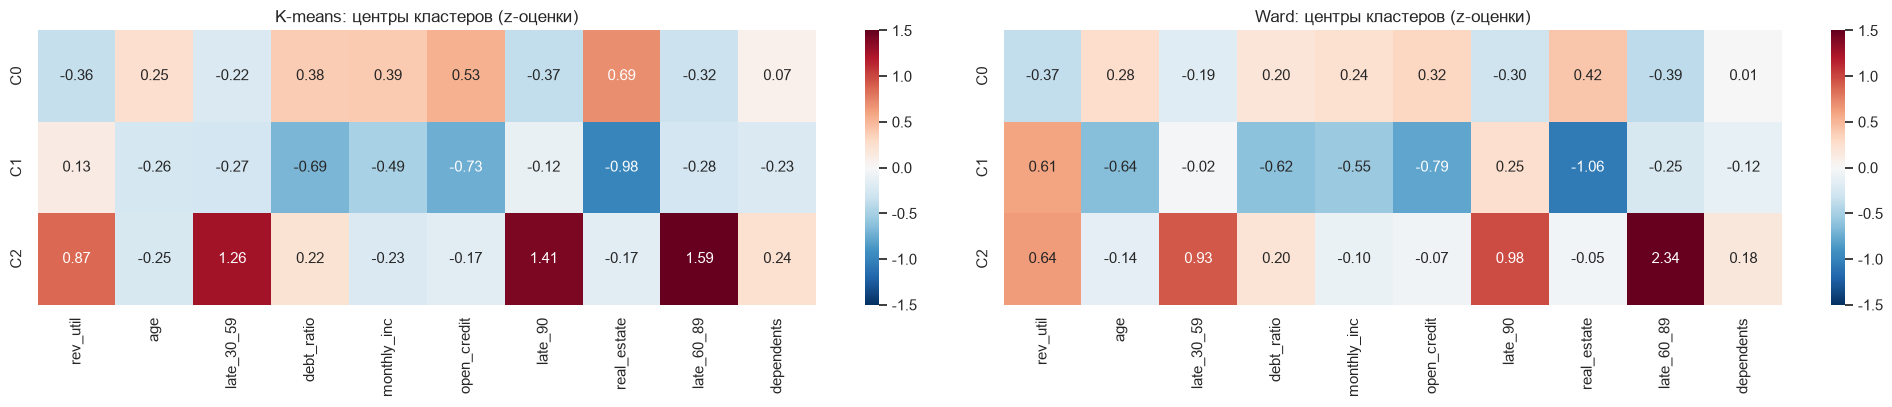

In [26]:
def profile(lab):
    p = X_raw.groupby(lab).median()
    p.insert(0, "размер", np.bincount(lab))
    p["ср. число просрочек"] = X_raw[late_cols].sum(axis=1).groupby(lab).mean()
    p["доля без просрочек"] = (X_raw[late_cols].sum(axis=1) == 0).groupby(lab).mean()
    p["доля dlq_2yrs=1"] = pd.Series(y).groupby(lab).mean()
    p.index = [f"C{i}" for i in p.index]
    return p

prof_km, prof_hc = profile(lab_km), profile(lab_hc)
print("K-means: медианы признаков в исходных единицах")
display(prof_km.style.format("{:.2f}"))
print("Ward: медианы признаков в исходных единицах")
display(prof_hc.style.format("{:.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(20, 4.2))
for ax, (name, lab) in zip(axes, [("K-means", lab_km), ("Ward", lab_hc)]):
    C = pd.DataFrame(centers_of(Z, lab), columns=FEATURES, index=[f"C{i}" for i in range(K)])
    sns.heatmap(C, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, ax=ax)
    ax.set_title(f"{name}: центры кластеров (z-оценки)")
plt.tight_layout()
plt.show()

**Интерпретация кластеров (K-means; у Ward портреты аналогичны).**

| Кластер | Размер | Портрет (медианы) | Доля просрочек | Название сегмента |
|---|---|---|---|---|
| **C0** | 8 293 (51%) | возраст 52, доход 6 500, 10 открытых кредитов, 2 ипотеки, загрузка лимитов 23%, долговая нагрузка 0.42; 73% без единой просрочки | **37.6%** | **«Зрелые благополучные заёмщики»**: длинная кредитная история, недвижимость, высокий доход, кредитные карты используются умеренно. Нагрузка высокая из-за ипотеки, но обслуживается. |
| **C1** | 5 395 (33%) | возраст 42, доход 3 632, 5 кредитов, нет ипотеки, загрузка лимитов 59%, долговая нагрузка 0.13, иждивенцев 0 | **47.9%** | **«Молодые клиенты с ограниченной историей»**: низкий доход, мало кредитов, без недвижимости. Карты используются наполовину. Риск средний, близкий к общему уровню. |
| **C2** | 2 625 (16%) | возраст 45, доход 4 223, 6 кредитов, **загрузка лимитов 97%**, у всех есть просрочки (в среднем 4.6), медиана 2 просрочки 30–59 дн. и по 1 в каждой из более тяжёлых категорий | **93.1%** | **«Проблемные заёмщики»**: лимиты исчерпаны, систематические просрочки. Почти все допустили серьёзную просрочку. |

* Сегменты соответствуют гипотезе из введения. Каждый можно использовать на практике: C0 — кросс-продажи и снижение ставок, C1 — осторожное увеличение лимитов и развитие кредитной истории, C2 — взыскание, реструктуризация, запрет новых кредитов.
* **Отличия Ward:** C1 моложе (медиана 38 лет) и сильнее закредитован (загрузка лимитов 90%, у 54% есть просрочки), поэтому доля просрочек там 64%. C0 крупнее (10 216) и поглощает «средних» клиентов. Ward проводит границу C0/C1 по загрузке лимитов, а K-means — по «зрелости» (кредиты, ипотека, доход).

### 5.3. Сравнение методов и устойчивость выделенных групп

Согласованность методов: ARI = 0.490, NMI = 0.434, доля объектов в «одноимённых» кластерах = 0.801


Ward,0,1,2
K-means,,,
0,7906,126,261
1,1926,3372,97
2,384,451,1790


,K-means,Ward
среднее ARI,0.984,0.641
СКО,0.010,0.086
мин,0.960,0.487
макс,0.995,0.751


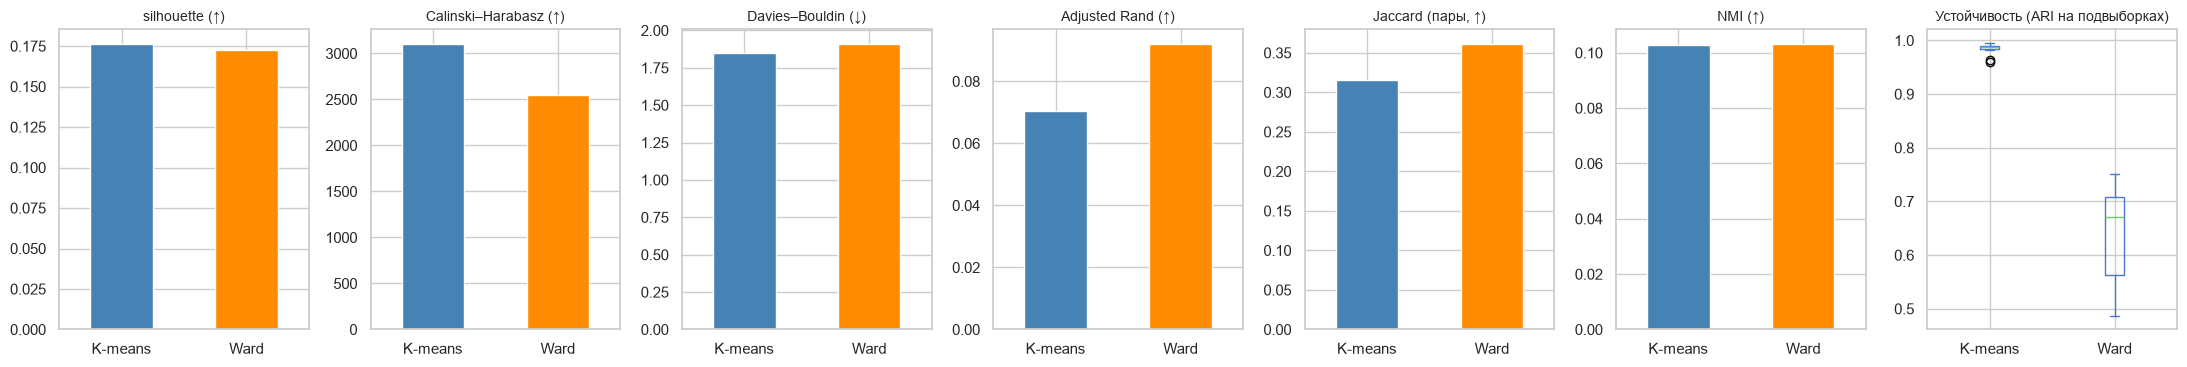

In [27]:
ct = pd.crosstab(pd.Series(lab_km, name="K-means"), pd.Series(lab_hc, name="Ward"))
print(f"Согласованность методов: ARI = {adjusted_rand_score(lab_km, lab_hc):.3f}, "
      f"NMI = {normalized_mutual_info_score(lab_km, lab_hc):.3f}, "
      f"доля объектов в «одноимённых» кластерах = {(lab_km == lab_hc).mean():.3f}")
display(ct)

# Устойчивость на подвыборках: 15 раз берём 70% объектов, повторяем кластеризацию
# и сравниваем с исходными метками на тех же объектах
boot = []
rng = np.random.default_rng(SEED)
for b in range(15):
    idx = rng.choice(len(Z), int(0.7 * len(Z)), replace=False)
    l_km = KMeans(n_clusters=K, n_init=10, random_state=b).fit_predict(Z[idx])
    l_hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z[idx])
    boot.append({"K-means": adjusted_rand_score(lab_km[idx], l_km), "Ward": adjusted_rand_score(lab_hc[idx], l_hc)})
boot = pd.DataFrame(boot)
display(boot.describe().loc[["mean", "std", "min", "max"]].rename(index={"mean": "среднее ARI", "std": "СКО", "min": "мин", "max": "макс"}))

cmp_cols = ["silhouette (↑)", "Calinski–Harabasz (↑)", "Davies–Bouldin (↓)", "Adjusted Rand (↑)", "Jaccard (пары, ↑)", "NMI (↑)"]
fig, axes = plt.subplots(1, len(cmp_cols) + 1, figsize=(22, 3.8))
for ax, col in zip(axes, cmp_cols):
    metrics.loc[col, ["K-means (k=3)", "Иерархическая Ward (k=3)"]].plot.bar(ax=ax, color=["steelblue", "darkorange"], rot=0)
    ax.set_title(col, fontsize=10); ax.set_xticklabels(["K-means", "Ward"])
boot.plot.box(ax=axes[-1]); axes[-1].set_title("Устойчивость (ARI на подвыборках)", fontsize=10)
plt.tight_layout()
plt.show()

**Пояснение к сравнению.**

* **Согласованность методов:** ARI(K-means, Ward) = 0.49, NMI = 0.43. **80% объектов** получили одинаковый кластер. Расхождения в основном связаны с 1 926 объектами из C1 по K-means, которые Ward отнёс к C0: это граница «зрелые / молодые», где плотность данных непрерывна. Кластер C2 оба метода выделяют похоже: 1 790 общих объектов, ~68% кластера K-means.
* **Устойчивость на подвыборках** (15 раз по 70% объектов):
  * **K-means:** ARI с исходным разбиением **0.984 ± 0.010** (минимум 0.96), разбиение воспроизводится практически полностью.
  * **Ward:** **0.64 ± 0.09** (от 0.49 до 0.75). Иерархия чувствительна к составу выборки: другое раннее слияние меняет всю дальнейшую структуру дерева.
* **Итог по метрикам:** K-means лучше по всем внутренним метрикам (силуэт, CH, DB, WCSS) и намного устойчивее. Ward немного лучше по внешним метрикам (ARI 0.092 против 0.071, Jaccard 0.36 против 0.32), то есть точнее отделяет рискованных заёмщиков, но ценой меньшей стабильности.

## 6. Заключение

1. **Данные.** Credit Risk Benchmark: 16 714 заёмщиков, 10 числовых признаков, без пропусков, классы сбалансированы. Ни один признак не распределён нормально. В данных есть служебные коды (96/98), ошибки (нулевой доход, `rev_util` до 22 000) и сильная правая асимметрия.
2. **Предобработка.** Удалены 401 аномальная запись (2.4%), хвосты винзоризованы по 1/99-му перцентилям, асимметричные признаки логарифмированы, затем применён `StandardScaler`. Он выбран потому, что обеспечивает равный вклад признаков в евклидово расстояние, на котором основаны оба метода.
3. **Кластерная тенденция.** Статистика Хопкинса 0.77 подтверждает, что данные неоднородны и кластеризация имеет смысл. Однако матрица рассеивания и PCA показывают перекрывающиеся эллипсоидальные группы без разрывов плотности.
4. **Число кластеров.** Силуэт и CH формально максимальны при k = 2, «локоть» размыт (Kneedle указывает k = 5). DB, скачки высот дендрограммы и интерпретируемость указывают на **k = 3**. Это число выбрано для обоих методов.
5. **Качество.** K-means: силуэт 0.177, CH 3 107, DB 1.85. Ward: 0.172, 2 551, 1.91. Отношение межкластерного расстояния к внутрикластерному ≈ 0.95, то есть **кластерная структура слабая, но статистически реальная** (у случайного разбиения силуэт ≈ 0). Внешние метрики относительно класса умеренные: ARI 0.07–0.09, Rand 0.54, Jaccard 0.32–0.36.
6. **Параметры.**
   * С ростом k WCSS монотонно падает, силуэт снижается с 0.20 до 0.14, согласие с классом максимально при k = 2 (ARI 0.14) и ниже при больших k.
   * `n_init = 10` необходим: при одной инициализации и k = 3 решения различаются вплоть до ARI = 0.41.
   * Из типов связи только Ward даёт содержательные кластеры: single и average вырождаются в «одиночные выбросы + всё остальное».
   * DBSCAN при любых ε и min_samples либо объявляет шумом большинство объектов, либо сливает всё в один кластер.
7. **Интерпретация.** Выделены три сегмента заёмщиков:
   * **«зрелые благополучные»** — 51%, доля просрочек 38%;
   * **«молодые с ограниченной историей»** — 33%, 48%;
   * **«проблемные»** — 16%, 93%: исчерпанные лимиты и систематические просрочки.

   Метка не использовалась при обучении, и то, что оба метода нашли группу с 90%+ просрочек, подтверждает практическую ценность кластеризации.
8. **Сравнение методов.** **K-means эффективнее** для этих данных: лучше все внутренние метрики, выше устойчивость (ARI на подвыборках 0.98 против 0.64), линейная сложность по числу объектов. Иерархическая кластеризация Уорда полезна на этапе разведки (дендрограмма помогает выбрать k) и немного точнее отделяет рискованных заёмщиков. Но она требует O(n²) памяти и чувствительна к составу выборки.
9. **Применимость.** Для финансовых данных с плавной структурой, большим числом дискретных признаков и перекрывающимися группами подходят методы, минимизирующие внутрикластерную дисперсию (K-means, Ward), при обязательной обработке выбросов и асимметрии. Плотностные методы (DBSCAN) и связи single/average неприменимы. Кластеризацию стоит рассматривать как инструмент сегментации, а не замену классификатору риска.

## 7. Список источников

1. Credit Risk Benchmark Dataset. — Kaggle. — URL: https://www.kaggle.com/datasets/adilshamim8/credit-risk-benchmark-dataset
2. Give Me Some Credit (исходные данные, описание признаков). — Kaggle Competition. — URL: https://www.kaggle.com/c/GiveMeSomeCredit
3. scikit-learn User Guide: Clustering. — URL: https://scikit-learn.org/stable/modules/clustering.html
4. scikit-learn User Guide: Clustering performance evaluation. — URL: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
5. SciPy: Hierarchical clustering (`scipy.cluster.hierarchy`). — URL: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html
6. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. — 2nd ed. — Springer, 2009. — Гл. 14.3 «Cluster Analysis».
7. Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis // Journal of Computational and Applied Mathematics. — 1987. — Vol. 20. — P. 53–65.
8. Ester M., Kriegel H.-P., Sander J., Xu X. A density-based algorithm for discovering clusters in large spatial databases with noise (DBSCAN) // Proc. KDD-96. — 1996. — P. 226–231.
9. Hubert L., Arabie P. Comparing partitions // Journal of Classification. — 1985. — Vol. 2. — P. 193–218 (Adjusted Rand Index).
10. Satopää V. et al. Finding a "Kneedle" in a Haystack: Detecting Knee Points in System Behavior // ICDCS Workshops. — 2011.

## 8. Приложение. Листинг программного кода

Полный программный код приведён в ячейках ноутбука выше, в порядке выполнения: загрузка → анализ → предобработка → подбор k → кластеризация → метрики → исследование параметров → визуализация → сравнение. Исходник ноутбука также лежит в репозитории: `build_notebook.py` (код ячеек) и `md_text.py` (текст пояснений).

Воспроизведение: `pip install -r requirements.txt`, затем выполнить все ячейки (`Run All`, ~2 минуты). Все случайные процессы зафиксированы `random_state = 42`.

Версии библиотек:

In [28]:
import sys, sklearn, scipy, matplotlib
print("Python", sys.version.split()[0])
for lib in [np, pd, sklearn, scipy, matplotlib, sns]:
    print(f"{lib.__name__:12s} {lib.__version__}")

Python 3.12.16
numpy        2.5.4
pandas       3.1.1
sklearn      1.9.1
scipy        1.18.1
matplotlib   3.11.2
seaborn      0.13.2
